# AI Campaign Analyst — iPinYou Advertiser 1458

## 1. Project Introduction

### Project Overview

This project analyzes advertising campaign data from the iPinYou Real-Time Bidding (RTB) dataset.

The analysis focuses on advertiser **1458** and explores bidding activity, impressions, clicks, conversions, advertising prices, creatives, and audience distribution.

### Project Objectives

- Inspect and understand raw advertising data.
- Ingest and process data using Python, Pandas, and DuckDB.
- Clean and validate advertising datasets.
- Export processed datasets into Parquet format.
- Analyze campaign activity and advertising performance.
- Identify useful patterns and present findings through data analysis and visualizations.

### Dataset Information

- **Dataset:** iPinYou Season 2
- **Advertiser ID:** 1458
- **Campaign data period:** June 6–12, 2013
- **Primary tools:** Python, Pandas, DuckDB, SQL, Matplotlib
- **Storage format:** Parquet

### Project Scope

The analysis covers four advertising event types:

1. Bids
2. Impressions
3. Clicks
4. Conversions

The project also examines advertising exchanges, creatives, ad-slot dimensions, hourly activity, and geographic distribution.

### Important Data Limitation

The available data contains only one conversion for advertiser 1458 during the seven-day period. Therefore, conversion-related conclusions should be interpreted cautiously.

## 2. Tools and Technologies

This project uses the following tools and technologies:

| Tool | Purpose |
|---|---|
| Python | Main programming language |
| Pandas | Data inspection and chunk-based processing |
| DuckDB | Data ingestion, SQL queries, and data analysis |
| SQL | Filtering, cleaning, aggregation, and analysis |
| Matplotlib | Data visualization |
| Parquet | Storage format for cleaned datasets |
| Jupyter Notebook | Interactive analysis environment |

### Processing Approach

The project follows these main stages:

1. Inspect the raw iPinYou dataset.
2. Identify advertiser 1458 records.
3. Ingest and process the data using Pandas and DuckDB.
4. Clean and validate the datasets.
5. Export cleaned datasets into Parquet files.
6. Perform exploratory data analysis.
7. Summarize campaign performance and findings.

In [2]:
import pandas as pd

In [4]:
df = pd.read_csv(
    "../data/ipinyou.contest.dataset-season2/training2nd/imp.20130606.txt.bz2",
    sep="\t",
    header=None,
    compression="bz2",
    dtype=str
)

In [5]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
0,8a15b98c8f9e60d4f92aaab01acf52a4,20130606000104192,1,VhTVORqG36N6qMj,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,114.100.37.*,106,117,1,lsxSl559Xql7FmMs,...,90,0,1,0,23d6dade7ed21cea308205b37594003e,227,207,b2e35064f3549d447edbbdfb1f707c8c,3427,"10063,10684,10083,13403,10059,10024,10048,1005..."
1,5bd0cbeb2f82fb94e56b7dc2e6b77ec,20130606000104252,1,Vhkr1uaROqKsXmb,Mozilla/4.0 (compatible; MSIE 7.0; Windows NT ...,222.220.35.*,308,320,2,eSMvBpa0jqmUagk4JKTI,...,280,2,0,5,13606a7c541dcd9ca1948875a760bb31,238,72,d29e59bf0f7f8243858b8183f14d4412,3358,"13800,10024"
2,faf17eac9cabf1be598f4e75f40d501d,20130606000104253,1,VhL01pk8OTkW3Mc,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,58.100.240.*,94,95,1,tK1NTu1YP5scFsf,...,90,0,1,0,d5cecca9a6cbd7a0a48110f1306b26d1,227,108,d29e59bf0f7f8243858b8183f14d4412,3358,"10059,13866,10063,10111"
3,234870d3864ad1852fe04b172f340be3,20130606000104308,1,VhT3La5uDlaywOj,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,122.233.40.*,94,95,1,trqRTummPvas1m58uG,...,250,2,1,0,44966cc8da1ed40c95d59e863c8c75f0,300,81,361e128affece850342293213691a043,3386,"10057,10063,10024,13800,13866,10110"
4,20fb85784972aebed3dda8d20ca87afb,20130606000104329,1,VhkSPnNDP8L8eYl,Opera/9.80 (Android; Opera Mini/7.7.33548/29.3...,58.67.157.*,216,217,1,trqRTuS8jZL7FmMs,...,250,0,5,0,d881a6c788e76c2c27ed1ef04f119544,227,89,d29e59bf0f7f8243858b8183f14d4412,3358,"13866,10111"


In [6]:
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

Total rows: 1821350
Total columns: 24


In [7]:
advertiser_1458 = df[df.iloc[:, 22] == "1458"]

print("Records for advertiser 1458:", len(advertiser_1458))

Records for advertiser 1458: 448164


In [8]:
cols = [
    "bid_id", "timestamp", "log_type", "ipinyou_id", "user_agent",
    "ip", "region", "city", "ad_exchange", "domain", "url",
    "anonymous_url_id", "ad_slot_id", "ad_slot_width",
    "ad_slot_height", "ad_slot_visibility", "ad_slot_format",
    "ad_slot_floor_price", "creative_id", "bidding_price",
    "paying_price", "key_page_url", "advertiser_id", "user_tags"
]

df.columns = cols

df.head()

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_height,ad_slot_visibility,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id,user_tags
0,8a15b98c8f9e60d4f92aaab01acf52a4,20130606000104192,1,VhTVORqG36N6qMj,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,114.100.37.*,106,117,1,lsxSl559Xql7FmMs,...,90,0,1,0,23d6dade7ed21cea308205b37594003e,227,207,b2e35064f3549d447edbbdfb1f707c8c,3427,"10063,10684,10083,13403,10059,10024,10048,1005..."
1,5bd0cbeb2f82fb94e56b7dc2e6b77ec,20130606000104252,1,Vhkr1uaROqKsXmb,Mozilla/4.0 (compatible; MSIE 7.0; Windows NT ...,222.220.35.*,308,320,2,eSMvBpa0jqmUagk4JKTI,...,280,2,0,5,13606a7c541dcd9ca1948875a760bb31,238,72,d29e59bf0f7f8243858b8183f14d4412,3358,"13800,10024"
2,faf17eac9cabf1be598f4e75f40d501d,20130606000104253,1,VhL01pk8OTkW3Mc,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,58.100.240.*,94,95,1,tK1NTu1YP5scFsf,...,90,0,1,0,d5cecca9a6cbd7a0a48110f1306b26d1,227,108,d29e59bf0f7f8243858b8183f14d4412,3358,"10059,13866,10063,10111"
3,234870d3864ad1852fe04b172f340be3,20130606000104308,1,VhT3La5uDlaywOj,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,122.233.40.*,94,95,1,trqRTummPvas1m58uG,...,250,2,1,0,44966cc8da1ed40c95d59e863c8c75f0,300,81,361e128affece850342293213691a043,3386,"10057,10063,10024,13800,13866,10110"
4,20fb85784972aebed3dda8d20ca87afb,20130606000104329,1,VhkSPnNDP8L8eYl,Opera/9.80 (Android; Opera Mini/7.7.33548/29.3...,58.67.157.*,216,217,1,trqRTuS8jZL7FmMs,...,250,0,5,0,d881a6c788e76c2c27ed1ef04f119544,227,89,d29e59bf0f7f8243858b8183f14d4412,3358,"13866,10111"


In [9]:
df.isnull().sum()

bid_id                       0
timestamp                    0
log_type                     0
ipinyou_id                   0
user_agent                 280
ip                           0
region                       0
city                         0
ad_exchange                  0
domain                   98186
url                      18123
anonymous_url_id       1821350
ad_slot_id                   0
ad_slot_width                0
ad_slot_height               0
ad_slot_visibility           0
ad_slot_format               0
ad_slot_floor_price          0
creative_id                  0
bidding_price                0
paying_price                 0
key_page_url                 0
advertiser_id                0
user_tags               220841
dtype: int64

In [10]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent.sort_values(ascending=False)

anonymous_url_id       100.000000
user_tags               12.125127
domain                   5.390836
url                      0.995031
user_agent               0.015373
ad_slot_height           0.000000
advertiser_id            0.000000
key_page_url             0.000000
paying_price             0.000000
bidding_price            0.000000
creative_id              0.000000
ad_slot_floor_price      0.000000
ad_slot_format           0.000000
ad_slot_visibility       0.000000
bid_id                   0.000000
ad_slot_width            0.000000
timestamp                0.000000
ad_exchange              0.000000
city                     0.000000
region                   0.000000
ip                       0.000000
ipinyou_id               0.000000
log_type                 0.000000
ad_slot_id               0.000000
dtype: float64

In [11]:
df["advertiser_id"].value_counts()

advertiser_id
1458    448164
3386    435900
3427    393516
3476    354398
3358    189372
Name: count, dtype: int64

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1821350 entries, 0 to 1821349
Data columns (total 24 columns):
 #   Column               Dtype
---  ------               -----
 0   bid_id               str  
 1   timestamp            str  
 2   log_type             str  
 3   ipinyou_id           str  
 4   user_agent           str  
 5   ip                   str  
 6   region               str  
 7   city                 str  
 8   ad_exchange          str  
 9   domain               str  
 10  url                  str  
 11  anonymous_url_id     str  
 12  ad_slot_id           str  
 13  ad_slot_width        str  
 14  ad_slot_height       str  
 15  ad_slot_visibility   str  
 16  ad_slot_format       str  
 17  ad_slot_floor_price  str  
 18  creative_id          str  
 19  bidding_price        str  
 20  paying_price         str  
 21  key_page_url         str  
 22  advertiser_id        str  
 23  user_tags            str  
dtypes: str(24)
memory usage: 333.5 MB


In [13]:
df[["ad_slot_floor_price", "bidding_price", "paying_price"]].head(10)

,ad_slot_floor_price,bidding_price,paying_price
0,0,227,207
1,5,238,72
2,0,227,108
3,0,300,81
4,0,227,89
5,5,300,5
6,5,238,126
7,0,227,11
8,16,238,50
9,5,300,64


In [14]:
df[["ad_slot_floor_price", "bidding_price", "paying_price"]].dtypes

ad_slot_floor_price    str
bidding_price          str
paying_price           str
dtype: object

In [15]:
# --------------------------------------------------
# STEP 6: CONVERT PRICE COLUMNS TO NUMERIC DATA TYPES
# --------------------------------------------------

# These are the three price-related columns we want to convert.
# Currently, pandas stores them as strings (text).
price_columns = [
    "ad_slot_floor_price",
    "bidding_price",
    "paying_price"
]

# Loop through each price column and convert its values into numbers.
for col in price_columns:

    # pd.to_numeric() converts text values into numeric values.
    # errors="coerce" changes invalid values into NaN (missing values)
    # instead of producing an error.
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [16]:
# --------------------------------------------------
# STEP 7: CHECK THE DATA TYPES AFTER CONVERSION
# --------------------------------------------------

# Display the data types of our three price columns.
# We expect numeric types such as int64 or float64,
# instead of str (string).
df[price_columns].dtypes

ad_slot_floor_price    int64
bidding_price          int64
paying_price           int64
dtype: object

In [17]:
# --------------------------------------------------
# STEP 8: FILTER DATA FOR ADVERTISER 1458
# --------------------------------------------------

# Select only records where advertiser_id equals 1458.
# This removes records belonging to the other four advertisers.
df_1458 = df[df["advertiser_id"] == "1458"].copy()

# Display the number of records belonging to advertiser 1458.
print("Advertiser 1458 records:", len(df_1458))

Advertiser 1458 records: 448164


In [18]:
# --------------------------------------------------
# STEP 9: DESCRIPTIVE STATISTICS FOR ADVERTISER 1458
# --------------------------------------------------

# Calculate statistical summaries for the three price columns.
# This includes:
# count  = number of available values
# mean   = average
# std    = standard deviation
# min    = smallest value
# 25%    = first quartile
# 50%    = median
# 75%    = third quartile
# max    = largest value

df_1458[price_columns].describe()

,ad_slot_floor_price,bidding_price,paying_price
count,448164.000000,448164.0,448164.000000
mean,25.539722,300.0,67.155394
std,35.384377,0.0,55.871971
min,0.000000,300.0,0.000000
25%,0.000000,300.0,26.000000
50%,5.000000,300.0,55.000000
75%,50.000000,300.0,80.000000
max,295.000000,300.0,300.000000


In [19]:
# --------------------------------------------------
# STEP 11: COMPARE BIDDING PRICE AND PAYING PRICE
# --------------------------------------------------

# Calculate the difference between the price offered
# and the actual price paid for each impression record.
df_1458["bid_payment_difference"] = (
    df_1458["bidding_price"] - df_1458["paying_price"]
)

# Calculate the average difference.
average_difference = df_1458["bid_payment_difference"].mean()

# Display the result.
print("Average bid-payment difference:", average_difference)

Average bid-payment difference: 232.8446059924492


Matplotlib is building the font cache; this may take a moment.


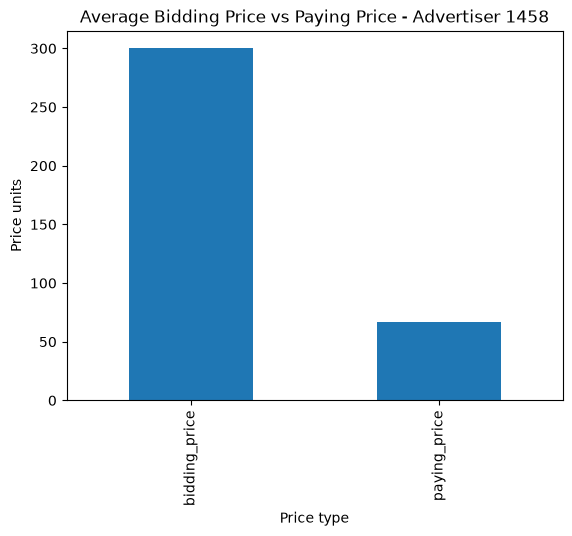

In [21]:
# --------------------------------------------------
# STEP 12: VISUALIZE AVERAGE BIDDING AND PAYING PRICES
# --------------------------------------------------

import matplotlib.pyplot as plt

# Calculate the average values for the two price columns.
average_prices = df_1458[
    ["bidding_price", "paying_price"]
].mean()

# Create a bar chart to compare the average prices.
average_prices.plot(
    kind="bar",
    title="Average Bidding Price vs Paying Price - Advertiser 1458",
    ylabel="Price units",
    xlabel="Price type"
)

# Display the chart.
plt.show()

In [22]:
# --------------------------------------------------
# STEP 13: CHECK LOG TYPES IN THE IMPRESSION DATA
# --------------------------------------------------

# Count how many records belong to each log type.
df["log_type"].value_counts(dropna=False)

log_type
1    1821350
Name: count, dtype: int64

In [23]:
# --------------------------------------------------
# STEP 14: INSPECT THE TIMESTAMP COLUMN
# --------------------------------------------------

# Display the first 10 timestamps.
df["timestamp"].head(10)

0    20130606000104192
1    20130606000104252
2    20130606000104253
3    20130606000104308
4    20130606000104329
5    20130606000104371
6    20130606000104399
7    20130606000104407
8    20130606000104412
9    20130606000104420
Name: timestamp, dtype: str

In [24]:
# Display the earliest and latest timestamps.
print("Earliest timestamp:", df["timestamp"].min())
print("Latest timestamp:", df["timestamp"].max())

Earliest timestamp: 20130606000104192
Latest timestamp: 20130606234840179


In [25]:
# --------------------------------------------------
# STEP 15: CONVERT TIMESTAMPS TO DATETIME
# --------------------------------------------------

# Convert the timestamp strings into proper datetime values.
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    format="%Y%m%d%H%M%S%f"
)

# Display the original timestamp and the converted datetime.
df[["timestamp", "datetime"]].head(10)

,timestamp,datetime
0,20130606000104192,2013-06-06 00:01:04.192
1,20130606000104252,2013-06-06 00:01:04.252
2,20130606000104253,2013-06-06 00:01:04.253
3,20130606000104308,2013-06-06 00:01:04.308
4,20130606000104329,2013-06-06 00:01:04.329
5,20130606000104371,2013-06-06 00:01:04.371
6,20130606000104399,2013-06-06 00:01:04.399
7,20130606000104407,2013-06-06 00:01:04.407
8,20130606000104412,2013-06-06 00:01:04.412
9,20130606000104420,2013-06-06 00:01:04.420


In [26]:
# --------------------------------------------------
# STEP 16: EXTRACT THE HOUR
# --------------------------------------------------

# Extract the hour from each datetime value.
# For example, 2013-06-06 14:25:30 becomes 14.
df["hour"] = df["datetime"].dt.hour

# Display the datetime and extracted hour.
df[["datetime", "hour"]].head(10)

,datetime,hour
0,2013-06-06 00:01:04.192,0
1,2013-06-06 00:01:04.252,0
2,2013-06-06 00:01:04.253,0
3,2013-06-06 00:01:04.308,0
4,2013-06-06 00:01:04.329,0
5,2013-06-06 00:01:04.371,0
6,2013-06-06 00:01:04.399,0
7,2013-06-06 00:01:04.407,0
8,2013-06-06 00:01:04.412,0
9,2013-06-06 00:01:04.420,0


In [27]:
# --------------------------------------------------
# STEP 17: COUNT IMPRESSIONS PER HOUR
# --------------------------------------------------

# Count the number of impression records for each hour.
hourly_impressions = df["hour"].value_counts().sort_index()

# Display the hourly impression counts.
hourly_impressions

hour
0      98548
1      27555
2      27607
3      29882
4      14231
5      15207
6      25916
7      36545
8      49785
9      63899
10    100668
11    103434
12    109494
13     84974
14     80674
15     82190
16    158933
17    122766
18    106854
19    104773
20    107094
21     96762
22    113362
23     60197
Name: count, dtype: int64

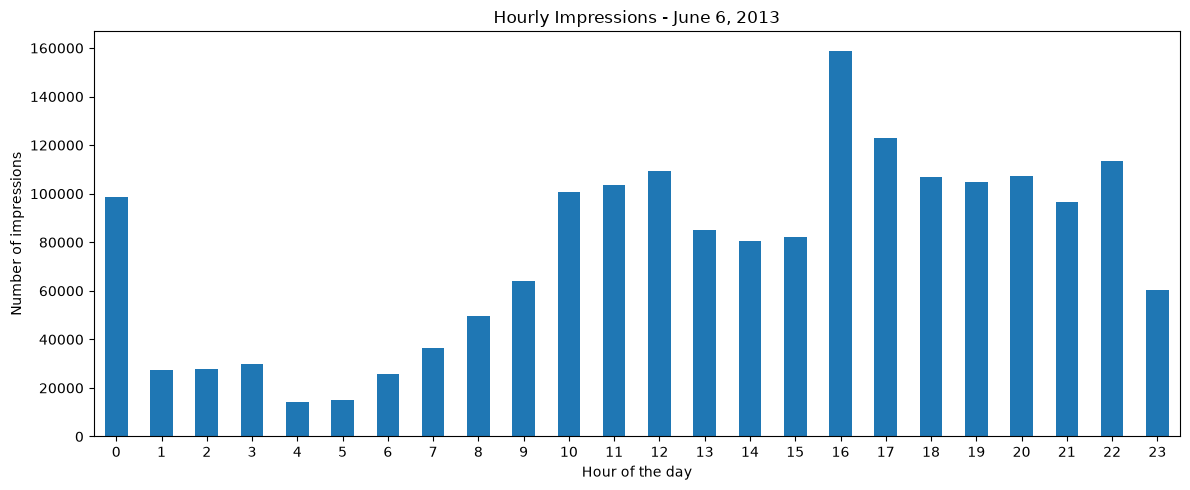

In [28]:
# --------------------------------------------------
# STEP 19: VISUALIZE HOURLY IMPRESSIONS
# --------------------------------------------------

import matplotlib.pyplot as plt

# Create a bar chart using hourly impression counts.
hourly_impressions.plot(
    kind="bar",
    figsize=(12, 5),
    title="Hourly Impressions - June 6, 2013",
    xlabel="Hour of the day",
    ylabel="Number of impressions"
)

# Display every hour on the horizontal axis.
plt.xticks(rotation=0)

# Adjust spacing so labels and title fit properly.
plt.tight_layout()

# Display the chart.
plt.show()

In [29]:
# --------------------------------------------------
# STEP 20: HOURLY IMPRESSIONS FOR ADVERTISER 1458
# --------------------------------------------------

# Filter the original dataframe to keep advertiser 1458.
# This also includes the datetime and hour columns we created.
df_1458 = df[df["advertiser_id"] == "1458"].copy()

# Count impressions for each hour for advertiser 1458.
hourly_impressions_1458 = (
    df_1458["hour"].value_counts().sort_index()
)

# Display the hourly impression counts.
hourly_impressions_1458

hour
0     20549
1      9905
2      6769
3      7340
4      3233
5      3994
6      3584
7     11239
8     11948
9     14609
10    25002
11    26100
12    25193
13    24881
14    26132
15    23908
16    25829
17    26874
18    24722
19    24750
20    26365
21    27574
22    28182
23    19482
Name: count, dtype: int64

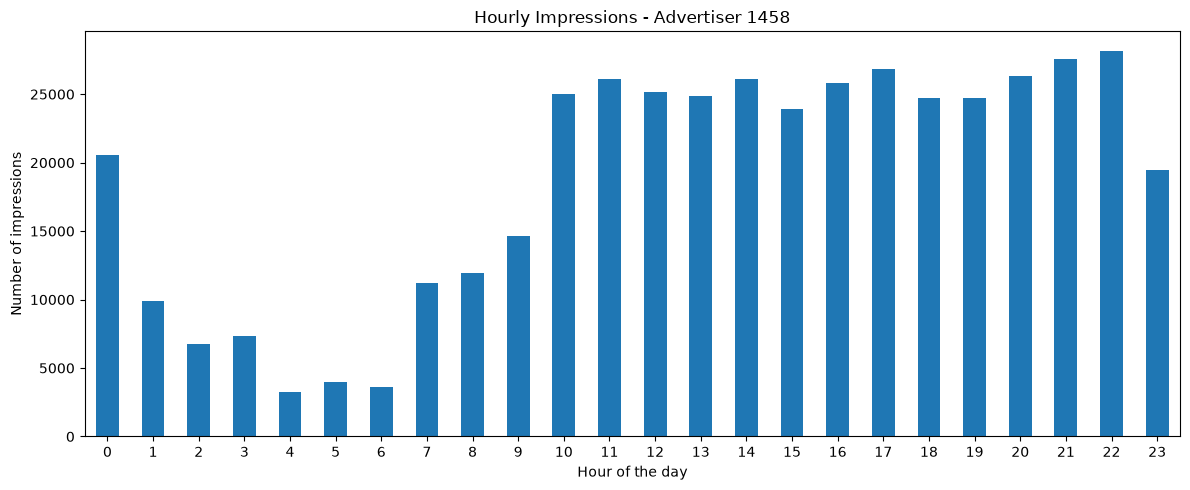

In [30]:
# --------------------------------------------------
# STEP 20B: VISUALIZE ADVERTISER 1458
# --------------------------------------------------

# Plot hourly impressions for advertiser 1458.
hourly_impressions_1458.plot(
    kind="bar",
    figsize=(12, 5),
    title="Hourly Impressions - Advertiser 1458",
    xlabel="Hour of the day",
    ylabel="Number of impressions"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
# --------------------------------------------------
# STEP 22: TOP 10 CITIES FOR ADVERTISER 1458
# --------------------------------------------------

# Count impressions for each city code.
top_cities = df_1458["city"].value_counts().head(10)

# Display the 10 cities with the most impressions.
top_cities

city
1      20212
219    16605
217    14191
79     12148
275    11727
85      9722
277     9542
334     7554
2       7465
0       6897
Name: count, dtype: int64

In [32]:
# --------------------------------------------------
# STEP 24: TOP 10 REGIONS FOR ADVERTISER 1458
# --------------------------------------------------

# Count impressions for each region code.
top_regions = df_1458["region"].value_counts().head(10)

# Display the 10 regions with the most impressions.
top_regions

region
216    53534
80     35204
146    29147
276    25948
94     22997
3      21220
164    20990
1      20212
183    17864
40     16322
Name: count, dtype: int64

In [33]:
# --------------------------------------------------
# STEP 26: COUNT UNIQUE CITIES AND REGIONS
# --------------------------------------------------

# Count the number of different city codes.
unique_cities = df_1458["city"].nunique()

# Count the number of different region codes.
unique_regions = df_1458["region"].nunique()

# Display the results.
print("Number of unique cities:", unique_cities)
print("Number of unique regions:", unique_regions)

Number of unique cities: 370
Number of unique regions: 35


In [34]:
# --------------------------------------------------
# STEP 27: CHECK CITY-TO-REGION RELATIONSHIPS
# --------------------------------------------------

# For each city, count how many different region codes appear.
city_region_counts = (
    df_1458.groupby("city")["region"].nunique()
)

# Count how many cities have 1, 2, 3, etc. different regions.
city_region_counts.value_counts().sort_index()

region
1    370
Name: count, dtype: int64

In [35]:
# --------------------------------------------------
# STEP 28: ANALYZE AD EXCHANGES
# --------------------------------------------------

# Count impressions for each ad exchange.
exchange_counts = df_1458["ad_exchange"].value_counts()

# Display the impression counts by exchange.
exchange_counts

ad_exchange
3    165988
1    150777
2    131399
Name: count, dtype: int64

In [36]:
# --------------------------------------------------
# STEP 30: CALCULATE AD EXCHANGE PERCENTAGES
# --------------------------------------------------

# Calculate the percentage of impressions from each exchange.
exchange_percentages = (
    df_1458["ad_exchange"]
    .value_counts(normalize=True) * 100
)

# Display percentages, rounded to two decimal places.
exchange_percentages = exchange_percentages.round(2)

exchange_percentages

ad_exchange
3    37.04
1    33.64
2    29.32
Name: proportion, dtype: float64

In [37]:
# --------------------------------------------------
# STEP 31: TOP 10 ADVERTISING DOMAINS
# --------------------------------------------------

# Count impressions for each domain.
top_domains = df_1458["domain"].value_counts().head(10)

# Display the top 10 domains.
top_domains

domain
31xSTvprdN1RFt             74965
5F1RQS9rg5scFsf            34641
DFpETuxoGQdcFNKbuKz        32796
trqRTuMvjTN7X9KbuKz        16722
5F97t5E0BTK7XhNrUMpENpn    15738
DDTSQuf0MTTNaqKIvMpENpn    13833
trqRTJkrBoq7JsNr5SqfNX     10420
trqRTvFRLpscFU              9099
trqRTvFoMNmIFY5SaMpENpn     8899
3FKElpuEMusyJqKbuKz         6212
Name: count, dtype: int64

In [38]:
# --------------------------------------------------
# STEP 32: TOP 10 ADVERTISING CREATIVES
# --------------------------------------------------

# Count impressions for each creative ID.
top_creatives = df_1458["creative_id"].value_counts().head(10)

# Display the top 10 creatives.
top_creatives

creative_id
832b91d59d0cb5731431653204a76c0e    107514
48f2e9ba15708c0146bda5e1dd653caa     98822
77819d3e0b3467fe5c7b16d68ad923a1     96492
cb7c76e7784031272e37af8e7e9b062c     45876
a499988a822facd86dd0e8e4ffef8532     42993
612599432d200b093719dd1f372f7a30     20986
2abc9eaf57d17a96195af3f63c45dc72     20000
fb5afa9dba1274beaf3dad86baf97e89     15481
Name: count, dtype: int64

In [39]:
# --------------------------------------------------
# STEP 33: ANALYZE AD SLOT DIMENSIONS
# --------------------------------------------------

# Count the different combinations of width and height.
slot_dimensions = (
    df_1458.groupby(
        ["ad_slot_width", "ad_slot_height"]
    ).size()
    .sort_values(ascending=False)
    .head(10)
)

# Display the 10 most common dimensions.
slot_dimensions

ad_slot_width  ad_slot_height
1000           90                107514
728            90                 98822
336            280                96492
160            600                45876
300            250                42993
468            60                 20986
250            250                20000
960            90                 15481
dtype: int64

In [40]:
# --------------------------------------------------
# STEP 34: ANALYZE AD SLOT FORMATS
# --------------------------------------------------

# Count impressions for each ad slot format.
slot_formats = df_1458["ad_slot_format"].value_counts()

# Display the results.
slot_formats

ad_slot_format
0    297387
1    150777
Name: count, dtype: int64

In [41]:
# --------------------------------------------------
# STEP 35: MISSING VALUES FOR ADVERTISER 1458
# --------------------------------------------------

# Count missing values in each column.
missing_counts = df_1458.isnull().sum()

# Calculate missing percentages.
missing_percentages = (
    df_1458.isnull().mean() * 100
).round(2)

# Combine the results into one table.
missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": missing_percentages
})

# Display columns that contain missing values.
missing_summary[missing_summary["missing_count"] > 0]

,missing_count,missing_percentage
user_agent,63,0.01
domain,25349,5.66
url,9395,2.10
anonymous_url_id,448164,100.00
user_tags,54667,12.20


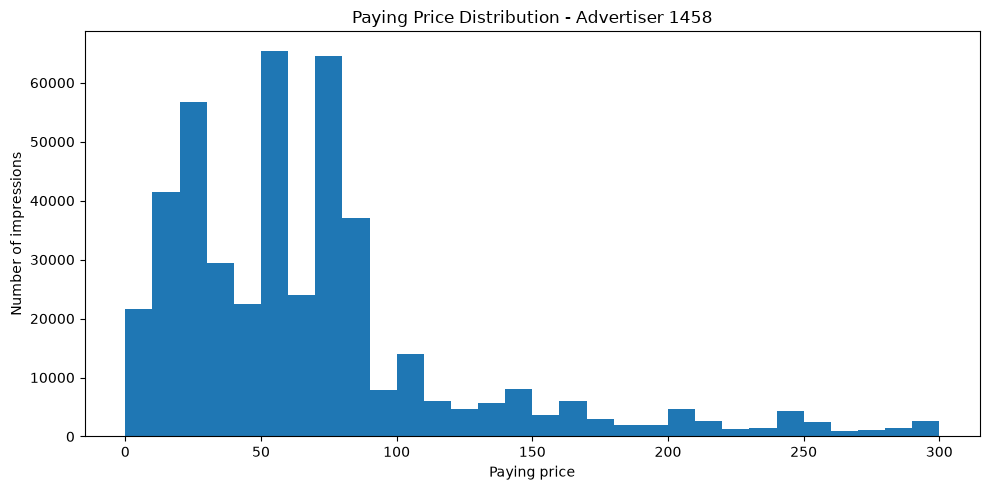

In [42]:
# --------------------------------------------------
# STEP 36: VISUALIZE PAYING PRICE DISTRIBUTION
# --------------------------------------------------

import matplotlib.pyplot as plt

# Create a histogram of paying prices.
df_1458["paying_price"].plot(
    kind="hist",
    bins=30,
    figsize=(10, 5),
    title="Paying Price Distribution - Advertiser 1458",
    xlabel="Paying price",
    ylabel="Number of impressions"
)

# Adjust the chart layout.
plt.tight_layout()

# Display the chart.
plt.show()

In [43]:
# --------------------------------------------------
# STEP 37: CHECK BIDDING PRICE VARIATION
# --------------------------------------------------

# Count the different bidding prices.
bidding_price_counts = (
    df_1458["bidding_price"].value_counts()
)

# Display the results.
bidding_price_counts

bidding_price
300    448164
Name: count, dtype: int64

In [44]:
# --------------------------------------------------
# STEP 38: FINAL DATA PROFILE
# --------------------------------------------------

# Create a dictionary containing important dataset statistics.
data_profile = {
    "Total impressions": len(df_1458),
    "Unique cities": df_1458["city"].nunique(),
    "Unique regions": df_1458["region"].nunique(),
    "Unique ad exchanges": df_1458["ad_exchange"].nunique(),
    "Unique domains": df_1458["domain"].nunique(),
    "Unique creatives": df_1458["creative_id"].nunique(),
    "Average bidding price": df_1458["bidding_price"].mean(),
    "Average paying price": df_1458["paying_price"].mean(),
    "Average floor price": df_1458["ad_slot_floor_price"].mean(),
    "Average bid-payment difference": (
        df_1458["bidding_price"] - df_1458["paying_price"]
    ).mean()
}

# Convert the dictionary into a pandas DataFrame.
profile_summary = pd.DataFrame(
    data_profile.items(),
    columns=["Metric", "Value"]
)

# Display the final profile.
profile_summary

,Metric,Value
0,Total impressions,448164.000000
1,Unique cities,370.000000
2,Unique regions,35.000000
3,Unique ad exchanges,3.000000
4,Unique domains,5933.000000
5,Unique creatives,8.000000
6,Average bidding price,300.000000
7,Average paying price,67.155394
8,Average floor price,25.539722
9,Average bid-payment difference,232.844606


In [45]:
# --------------------------------------------------
# STEP 39: SAVE ADVERTISER 1458 DATA
# --------------------------------------------------

# Create a folder for processed data if it does not exist.
from pathlib import Path

processed_folder = Path("../data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

# Save advertiser 1458's impression data.
df_1458.to_csv(
    processed_folder / "advertiser_1458_impressions_20130606.csv",
    index=False
)

print("Advertiser 1458 dataset saved successfully!")

Advertiser 1458 dataset saved successfully!


In [46]:
# --------------------------------------------------
# STEP 40: CREATE A DUCKDB DATABASE
# --------------------------------------------------

import duckdb
from pathlib import Path

# Locate the processed CSV file.
processed_file = Path(
    "../data/processed/advertiser_1458_impressions_20130606.csv"
).resolve()

# Choose where the DuckDB database will be stored.
database_file = Path(
    "../data/processed/campaign_analysis.duckdb"
).resolve()

# Connect to DuckDB (creates the database if it doesn't exist).
con = duckdb.connect(str(database_file))

print("DuckDB database created and connected!")
print("Database location:", database_file)
print("CSV file found:", processed_file.exists())

DuckDB database created and connected!
Database location: /Users/abrahameshete/dsp-campaign-analyst/data/processed/campaign_analysis.duckdb
CSV file found: True


In [47]:
# --------------------------------------------------
# STEP 41: LOAD CSV INTO DUCKDB
# --------------------------------------------------

# Create a table and import the CSV data.
con.execute("""
    CREATE OR REPLACE TABLE impressions_1458 AS
    SELECT *
    FROM read_csv_auto(?)
""", [str(processed_file)])

print("Data successfully loaded into DuckDB!")

Data successfully loaded into DuckDB!


In [48]:
# --------------------------------------------------
# STEP 42: VERIFY THE DUCKDB TABLE
# --------------------------------------------------

con.execute("""
    SELECT COUNT(*)
    FROM impressions_1458
""").fetchone()

(448164,)

In [49]:
# --------------------------------------------------
# STEP 43: INSPECT DUCKDB TABLE STRUCTURE
# --------------------------------------------------

con.execute("""
    DESCRIBE impressions_1458
""").df()

,column_name,column_type,null,key,default,extra
0,bid_id,VARCHAR,YES,None,None,None
1,timestamp,BIGINT,YES,None,None,None
2,log_type,BIGINT,YES,None,None,None
3,ipinyou_id,VARCHAR,YES,None,None,None
4,user_agent,VARCHAR,YES,None,None,None
5,ip,VARCHAR,YES,None,None,None
6,region,BIGINT,YES,None,None,None
7,city,BIGINT,YES,None,None,None
8,ad_exchange,BIGINT,YES,None,None,None
9,domain,VARCHAR,YES,None,None,None


In [50]:
# --------------------------------------------------
# STEP 44: CHECK MISSING VALUES
# --------------------------------------------------

con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) - COUNT(user_agent) AS missing_user_agent,
        COUNT(*) - COUNT(domain) AS missing_domain,
        COUNT(*) - COUNT(url) AS missing_url,
        COUNT(*) - COUNT(anonymous_url_id) AS missing_anonymous_url_id,
        COUNT(*) - COUNT(user_tags) AS missing_user_tags
    FROM impressions_1458
""").df()

,total_rows,missing_user_agent,missing_domain,missing_url,missing_anonymous_url_id,missing_user_tags
0,448164,63,25349,9395,448164,54667


In [51]:
# --------------------------------------------------
# STEP 45: CALCULATE MISSING-VALUE PERCENTAGES
# --------------------------------------------------

con.execute("""
    SELECT
        ROUND(100.0 * COUNT(*) FILTER (WHERE user_agent IS NULL) / COUNT(*), 2)
            AS user_agent_missing_pct,

        ROUND(100.0 * COUNT(*) FILTER (WHERE domain IS NULL) / COUNT(*), 2)
            AS domain_missing_pct,

        ROUND(100.0 * COUNT(*) FILTER (WHERE url IS NULL) / COUNT(*), 2)
            AS url_missing_pct,

        ROUND(100.0 * COUNT(*) FILTER (WHERE anonymous_url_id IS NULL) / COUNT(*), 2)
            AS anonymous_url_id_missing_pct,

        ROUND(100.0 * COUNT(*) FILTER (WHERE user_tags IS NULL) / COUNT(*), 2)
            AS user_tags_missing_pct

    FROM impressions_1458
""").df()

,user_agent_missing_pct,domain_missing_pct,url_missing_pct,anonymous_url_id_missing_pct,user_tags_missing_pct
0,0.01,5.66,2.1,100.0,12.2


In [52]:
# --------------------------------------------------
# STEP 46: CHECK DUPLICATE BID IDS
# --------------------------------------------------

con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT bid_id) AS unique_bid_ids,
        COUNT(*) - COUNT(DISTINCT bid_id) AS duplicate_bid_ids
    FROM impressions_1458
""").df()

,total_rows,unique_bid_ids,duplicate_bid_ids
0,448164,447312,852


In [53]:
# --------------------------------------------------
# STEP 47: INVESTIGATE DUPLICATE BID IDS
# --------------------------------------------------

con.execute("""
    SELECT
        bid_id,
        COUNT(*) AS occurrence_count
    FROM impressions_1458
    GROUP BY bid_id
    HAVING COUNT(*) > 1
    ORDER BY occurrence_count DESC
    LIMIT 10
""").df()

,bid_id,occurrence_count
0,b64a1de9a2516e5c00e96e5eb5081f16,6
1,9e73d53efaa3e435f74e09e8760bd6e9,5
2,d3bc281536c542daaccd7fb80bad6e7a,5
3,38840737661fa90bfa6024c67e60b99d,4
4,1c37ae2891e85d853f143eb56901d5dc,4
5,b0102b019174a2064700b2ed2b47c964,4
6,5f1b8965fd010dabfc828d4f3e66756a,4
7,35d2260c5a43623e05295140ae866182,4
8,ea9407e1f4307aac79651a1681534dcb,4
9,16834bda9ce5e37248aae03bc5365a03,4


In [54]:
# --------------------------------------------------
# STEP 48: INSPECT ONE REPEATED BID ID
# --------------------------------------------------

con.execute("""
    SELECT *
    FROM impressions_1458
    WHERE bid_id = 'b64a1de9a2516e5c00e96e5eb5081f16'
    ORDER BY datetime
""").df()

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id,user_tags,datetime,hour
0,b64a1de9a2516e5c00e96e5eb5081f16,20130606101612859,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:16:12.859,10
1,b64a1de9a2516e5c00e96e5eb5081f16,20130606101619152,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:16:19.152,10
2,b64a1de9a2516e5c00e96e5eb5081f16,20130606101619397,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:16:19.397,10
3,b64a1de9a2516e5c00e96e5eb5081f16,20130606101825755,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:18:25.755,10
4,b64a1de9a2516e5c00e96e5eb5081f16,20130606101826012,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:18:26.012,10
5,b64a1de9a2516e5c00e96e5eb5081f16,20130606101833177,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:18:33.177,10


In [56]:
# --------------------------------------------------
# STEP 49: CHECK EXACT DUPLICATE ROWS
# --------------------------------------------------

con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT (
            bid_id, timestamp, log_type, ipinyou_id,
            user_agent, ip, region, city, ad_exchange,
            domain, url, anonymous_url_id, ad_slot_id,
            ad_slot_width, ad_slot_height, ad_slot_visibility,
            ad_slot_format, ad_slot_floor_price, creative_id,
            bidding_price, paying_price, key_page_url,
            advertiser_id, user_tags, datetime, hour
        )) AS unique_complete_rows,
        COUNT(*) - COUNT(DISTINCT (
            bid_id, timestamp, log_type, ipinyou_id,
            user_agent, ip, region, city, ad_exchange,
            domain, url, anonymous_url_id, ad_slot_id,
            ad_slot_width, ad_slot_height, ad_slot_visibility,
            ad_slot_format, ad_slot_floor_price, creative_id,
            bidding_price, paying_price, key_page_url,
            advertiser_id, user_tags, datetime, hour
        )) AS exact_duplicate_rows
    FROM impressions_1458
""").df()

,total_rows,unique_complete_rows,exact_duplicate_rows
0,448164,448164,0


In [57]:
# --------------------------------------------------
# STEP 50: CHECK NUMERIC COLUMN QUALITY
# --------------------------------------------------

con.execute("""
    SELECT
        COUNT(*) FILTER (WHERE bidding_price IS NULL)
            AS missing_bidding_price,

        COUNT(*) FILTER (WHERE paying_price IS NULL)
            AS missing_paying_price,

        COUNT(*) FILTER (WHERE ad_slot_floor_price IS NULL)
            AS missing_floor_price,

        COUNT(*) FILTER (WHERE city IS NULL)
            AS missing_city,

        COUNT(*) FILTER (WHERE region IS NULL)
            AS missing_region,

        COUNT(*) FILTER (WHERE ad_exchange IS NULL)
            AS missing_ad_exchange

    FROM impressions_1458
""").df()

,missing_bidding_price,missing_paying_price,missing_floor_price,missing_city,missing_region,missing_ad_exchange
0,0,0,0,0,0,0


In [58]:
# --------------------------------------------------
# STEP 51: CHECK PRICE CONSISTENCY
# --------------------------------------------------

con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE paying_price > bidding_price
        ) AS paying_above_bid,

        COUNT(*) FILTER (
            WHERE bidding_price < ad_slot_floor_price
        ) AS bid_below_floor,

        COUNT(*) FILTER (
            WHERE paying_price < 0
        ) AS negative_paying_price,

        COUNT(*) FILTER (
            WHERE bidding_price < 0
        ) AS negative_bidding_price

    FROM impressions_1458
""").df()

,paying_above_bid,bid_below_floor,negative_paying_price,negative_bidding_price
0,0,0,0,0


In [59]:
# --------------------------------------------------
# STEP 52: CHECK TIMESTAMP CONSISTENCY
# --------------------------------------------------

con.execute("""
    SELECT
        MIN(datetime) AS first_impression,
        MAX(datetime) AS last_impression,
        COUNT(DISTINCT CAST(datetime AS DATE)) AS unique_dates,
        COUNT(*) FILTER (
            WHERE datetime IS NULL
        ) AS missing_datetime
    FROM impressions_1458
""").df()

,first_impression,last_impression,unique_dates,missing_datetime
0,2013-06-06 00:01:04.828,2013-06-06 23:46:00.850,1,0


In [60]:
# --------------------------------------------------
# STEP 53: VERIFY LOG TYPES
# --------------------------------------------------

con.execute("""
    SELECT
        log_type,
        COUNT(*) AS record_count
    FROM impressions_1458
    GROUP BY log_type
    ORDER BY log_type
""").df()

,log_type,record_count
0,1,448164


In [61]:
# --------------------------------------------------
# STEP 54: CHECK BIDDING PRICE DISTRIBUTION
# --------------------------------------------------

con.execute("""
    SELECT
        bidding_price,
        COUNT(*) AS impression_count,
        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM impressions_1458
    GROUP BY bidding_price
    ORDER BY bidding_price
""").df()

,bidding_price,impression_count,percentage
0,300,448164,100.0


In [62]:
# --------------------------------------------------
# STEP 55: CHECK PAYING PRICE DISTRIBUTION
# --------------------------------------------------

con.execute("""
    SELECT
        paying_price,
        COUNT(*) AS impression_count,
        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM impressions_1458
    GROUP BY paying_price
    ORDER BY impression_count DESC
    LIMIT 10
""").df()

,paying_price,impression_count,percentage
0,70,55493,12.38
1,50,36877,8.23
2,20,32901,7.34
3,80,23554,5.26
4,30,9589,2.14
5,19,8804,1.96
6,5,8086,1.80
7,40,7636,1.70
8,10,7262,1.62
9,64,6567,1.47


In [63]:
# --------------------------------------------------
# STEP 56: PAYING PRICE STATISTICS
# --------------------------------------------------

con.execute("""
    SELECT
        MIN(paying_price) AS minimum_price,
        MAX(paying_price) AS maximum_price,
        ROUND(AVG(paying_price), 2) AS average_price,
        MEDIAN(paying_price) AS median_price,
        ROUND(STDDEV(paying_price), 2) AS price_std_dev
    FROM impressions_1458
""").df()

,minimum_price,maximum_price,average_price,median_price,price_std_dev
0,0,300,67.16,55.0,55.87


In [64]:
# --------------------------------------------------
# STEP 57: CALCULATE BID-PAYMENT DIFFERENCE
# --------------------------------------------------

con.execute("""
    SELECT
        AVG(bidding_price) AS average_bid,
        AVG(paying_price) AS average_payment,

        AVG(bidding_price - paying_price)
            AS average_difference,

        ROUND(
            100.0 * AVG(bidding_price - paying_price)
            / AVG(bidding_price),
            2
        ) AS difference_percentage

    FROM impressions_1458
""").df()

,average_bid,average_payment,average_difference,difference_percentage
0,300.0,67.155394,232.844606,77.61


In [65]:
# --------------------------------------------------
# STEP 58: IMPRESSIONS BY AD EXCHANGE
# --------------------------------------------------

con.execute("""
    SELECT
        ad_exchange,
        COUNT(*) AS impression_count,

        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS impression_percentage,

        ROUND(AVG(paying_price), 2) AS average_paying_price

    FROM impressions_1458
    GROUP BY ad_exchange
    ORDER BY impression_count DESC
""").df()

,ad_exchange,impression_count,impression_percentage,average_paying_price
0,3,165988,37.04,60.35
1,1,150777,33.64,66.62
2,2,131399,29.32,76.37


In [66]:
# --------------------------------------------------
# STEP 59: TOP 10 MOST FREQUENTLY USED CREATIVES
# --------------------------------------------------

con.execute("""
    SELECT
        creative_id,
        COUNT(*) AS impression_count,

        ROUND(
            100.0 * COUNT(*) / (
                SELECT COUNT(*) FROM impressions_1458
            ),
            2
        ) AS impression_percentage

    FROM impressions_1458
    GROUP BY creative_id
    ORDER BY impression_count DESC
    LIMIT 10
""").df()

,creative_id,impression_count,impression_percentage
0,832b91d59d0cb5731431653204a76c0e,107514,23.99
1,48f2e9ba15708c0146bda5e1dd653caa,98822,22.05
2,77819d3e0b3467fe5c7b16d68ad923a1,96492,21.53
3,cb7c76e7784031272e37af8e7e9b062c,45876,10.24
4,a499988a822facd86dd0e8e4ffef8532,42993,9.59
5,612599432d200b093719dd1f372f7a30,20986,4.68
6,2abc9eaf57d17a96195af3f63c45dc72,20000,4.46
7,fb5afa9dba1274beaf3dad86baf97e89,15481,3.45


In [67]:
# --------------------------------------------------
# STEP 60: COUNT UNIQUE CREATIVES AND DOMAINS
# --------------------------------------------------

con.execute("""
    SELECT
        COUNT(DISTINCT creative_id) AS unique_creatives,
        COUNT(DISTINCT domain) AS unique_domains,
        COUNT(DISTINCT ad_slot_id) AS unique_ad_slots

    FROM impressions_1458
""").df()

,unique_creatives,unique_domains,unique_ad_slots
0,8,5933,14565


In [68]:
# --------------------------------------------------
# STEP 61: CREATE CLEANED ANALYTICAL TABLE
# --------------------------------------------------

con.execute("""
    CREATE OR REPLACE TABLE impressions_1458_clean AS
    SELECT * EXCLUDE (anonymous_url_id)
    FROM impressions_1458
""")

print("Cleaned analytical table created successfully!")

Cleaned analytical table created successfully!


In [69]:
# --------------------------------------------------
# STEP 62: VERIFY CLEANED TABLE
# --------------------------------------------------

con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) AS expected_rows,
        COUNT(*) - COUNT(DISTINCT bid_id) AS repeated_bid_id_occurrences
    FROM impressions_1458_clean
""").df()

,total_rows,expected_rows,repeated_bid_id_occurrences
0,448164,448164,852


In [70]:
# Check the cleaned table's structure

con.execute("""
    DESCRIBE impressions_1458_clean
""").df()

,column_name,column_type,null,key,default,extra
0,bid_id,VARCHAR,YES,None,None,None
1,timestamp,BIGINT,YES,None,None,None
2,log_type,BIGINT,YES,None,None,None
3,ipinyou_id,VARCHAR,YES,None,None,None
4,user_agent,VARCHAR,YES,None,None,None
5,ip,VARCHAR,YES,None,None,None
6,region,BIGINT,YES,None,None,None
7,city,BIGINT,YES,None,None,None
8,ad_exchange,BIGINT,YES,None,None,None
9,domain,VARCHAR,YES,None,None,None


In [71]:
# --------------------------------------------------
# STEP 63: VERIFY ROW COUNT
# --------------------------------------------------

con.execute("""
    SELECT
        (SELECT COUNT(*) FROM impressions_1458)
            AS original_rows,

        (SELECT COUNT(*) FROM impressions_1458_clean)
            AS cleaned_rows
""").df()

,original_rows,cleaned_rows
0,448164,448164


In [72]:
# --------------------------------------------------
# STEP 64: EXPORT CLEANED TABLE TO PARQUET
# --------------------------------------------------

parquet_file = Path(
    "../data/processed/advertiser_1458_impressions_20130606.parquet"
).resolve()

con.execute("""
    COPY impressions_1458_clean
    TO ?
    (FORMAT PARQUET, COMPRESSION ZSTD)
""", [str(parquet_file)])

print("Parquet file created successfully!")
print(parquet_file)

Parquet file created successfully!
/Users/abrahameshete/dsp-campaign-analyst/data/processed/advertiser_1458_impressions_20130606.parquet


In [73]:
# --------------------------------------------------
# STEP 65: VERIFY PARQUET FILE
# --------------------------------------------------

con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) AS verification_count
    FROM read_parquet(?)
""", [str(parquet_file)]).df()

,total_rows,verification_count
0,448164,448164


In [74]:
# --------------------------------------------------
# STEP 66: FIND THE OTHER LOG FILES
# --------------------------------------------------

from pathlib import Path

data_folder = Path(
    "../data/ipinyou.contest.dataset-season2/training2nd/"
)

for pattern in ["bid.20130606*", "clk.20130606*", "conv.20130606*"]:
    print(f"\nSearching for: {pattern}")

    for file in sorted(data_folder.glob(pattern)):
        print(file.name)


Searching for: bid.20130606*
bid.20130606.txt.bz2

Searching for: clk.20130606*
clk.20130606.txt.bz2

Searching for: conv.20130606*
conv.20130606.txt.bz2


In [75]:
# --------------------------------------------------
# STEP 67: INSPECT BID FILE
# --------------------------------------------------

import pandas as pd

bid_sample = pd.read_csv(
    data_folder / "bid.20130606.txt.bz2",
    sep="\t",
    header=None,
    compression="bz2",
    nrows=5,
    dtype=str
)

print("Shape:", bid_sample.shape)
display(bid_sample.head())

Shape: (5, 21)


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,b382c1c156dcbbd5b9317cb50f6a747b,20130606000104008,Vh16OwT6OQNUXbj,mozilla/4.0 (compatible; msie 6.0; windows nt ...,180.127.189.*,80,87,1,tFKETuqyMo1mjMp45SqfNX,249b2c34247d400ef1cd3c6bfda4f12a,...,mm_11402872_1272384_3182279,300,250,1,1,0,00fccc64a1ee2809348509b7ac2a97a5,227,3427,NaN
1,7b6195de0d14203f92001da653bf1de,20130606000104009,Vhkr1vpROHuhQWB,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,113.119.105.*,216,217,2,trqRTuToMTNUjM9r5rMi,74419a072f8927222a1fd8aaa18cce56,...,433287550,468,60,1,0,5,2f88fc9cf0141b5bbaf251cab07f4ce7,300,3386,NaN
2,2ea9fe21cf7350fcb5696d8cff0bbeaa,20130606000104012,VhKdLnuY3tlhXMa,mozilla/4.0 (compatible; msie 8.0; windows nt ...,42.184.148.*,65,69,1,trqRTvpogNlyDok4JKTI,134db65c2b66d8468d00bf42fd9f912f,...,mm_10032051_2374052_9219530,950,90,1,1,0,23d6dade7ed21cea308205b37594003e,227,3427,NaN
3,8a15b98c8f9e60d4f92aaab01acf52a4,20130606000104014,VhTVORqG36N6qMj,mozilla/5.0 (windows nt 5.1) applewebkit/537.1...,114.100.37.*,106,117,1,lsxSl559Xql7FmMs,8c9742e63497713b97ac7e780a8f9a12,...,mm_30232185_2681382_11190685,950,90,0,1,0,23d6dade7ed21cea308205b37594003e,227,3427,NaN
4,faf17eac9cabf1be598f4e75f40d501d,20130606000104016,VhL01pk8OTkW3Mc,mozilla/5.0 (windows nt 5.1) applewebkit/537.1...,58.100.240.*,94,95,1,tK1NTu1YP5scFsf,e22930480589abcc1468854cb3403314,...,mm_10075660_3500949_11453278,950,90,0,1,0,d5cecca9a6cbd7a0a48110f1306b26d1,227,3358,NaN


In [76]:
# --------------------------------------------------
# STEP 68: ASSIGN BID LOG COLUMN NAMES
# --------------------------------------------------

bid_columns = [
    "bid_id",
    "timestamp",
    "ipinyou_id",
    "user_agent",
    "ip",
    "region",
    "city",
    "ad_exchange",
    "domain",
    "url",
    "anonymous_url_id",
    "ad_slot_id",
    "ad_slot_width",
    "ad_slot_height",
    "ad_slot_visibility",
    "ad_slot_format",
    "ad_slot_floor_price",
    "creative_id",
    "bidding_price",
    "advertiser_id",
    "user_tags"
]

bid_sample.columns = bid_columns

print("Number of columns:", len(bid_sample.columns))
display(bid_sample.head())

Number of columns: 21


,bid_id,timestamp,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,url,...,ad_slot_id,ad_slot_width,ad_slot_height,ad_slot_visibility,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,advertiser_id,user_tags
0,b382c1c156dcbbd5b9317cb50f6a747b,20130606000104008,Vh16OwT6OQNUXbj,mozilla/4.0 (compatible; msie 6.0; windows nt ...,180.127.189.*,80,87,1,tFKETuqyMo1mjMp45SqfNX,249b2c34247d400ef1cd3c6bfda4f12a,...,mm_11402872_1272384_3182279,300,250,1,1,0,00fccc64a1ee2809348509b7ac2a97a5,227,3427,NaN
1,7b6195de0d14203f92001da653bf1de,20130606000104009,Vhkr1vpROHuhQWB,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,113.119.105.*,216,217,2,trqRTuToMTNUjM9r5rMi,74419a072f8927222a1fd8aaa18cce56,...,433287550,468,60,1,0,5,2f88fc9cf0141b5bbaf251cab07f4ce7,300,3386,NaN
2,2ea9fe21cf7350fcb5696d8cff0bbeaa,20130606000104012,VhKdLnuY3tlhXMa,mozilla/4.0 (compatible; msie 8.0; windows nt ...,42.184.148.*,65,69,1,trqRTvpogNlyDok4JKTI,134db65c2b66d8468d00bf42fd9f912f,...,mm_10032051_2374052_9219530,950,90,1,1,0,23d6dade7ed21cea308205b37594003e,227,3427,NaN
3,8a15b98c8f9e60d4f92aaab01acf52a4,20130606000104014,VhTVORqG36N6qMj,mozilla/5.0 (windows nt 5.1) applewebkit/537.1...,114.100.37.*,106,117,1,lsxSl559Xql7FmMs,8c9742e63497713b97ac7e780a8f9a12,...,mm_30232185_2681382_11190685,950,90,0,1,0,23d6dade7ed21cea308205b37594003e,227,3427,NaN
4,faf17eac9cabf1be598f4e75f40d501d,20130606000104016,VhL01pk8OTkW3Mc,mozilla/5.0 (windows nt 5.1) applewebkit/537.1...,58.100.240.*,94,95,1,tK1NTu1YP5scFsf,e22930480589abcc1468854cb3403314,...,mm_10075660_3500949_11453278,950,90,0,1,0,d5cecca9a6cbd7a0a48110f1306b26d1,227,3358,NaN


In [79]:
# --------------------------------------------------
# STEP 69: INGEST BID FILE USING PANDAS + DUCKDB
# --------------------------------------------------

import pandas as pd

# Read the compressed bid file
bid_df = pd.read_csv(
    bid_file,
    sep="\t",
    header=None,
    names=bid_columns,
    compression="bz2",
    dtype=str
)

# Register the pandas DataFrame with DuckDB
con.register("bid_df_temp", bid_df)

# Create a permanent DuckDB table
con.execute("""
    CREATE OR REPLACE TABLE bids_20130606 AS
    SELECT *
    FROM bid_df_temp
""")

# Remove the temporary registration
con.unregister("bid_df_temp")

print("Bid file loaded into DuckDB successfully!")
print("Total bid records:", len(bid_df))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Bid file loaded into DuckDB successfully!
Total bid records: 9586949


In [80]:
# Count bid records for each advertiser
con.execute("""
    SELECT
        advertiser_id,
        COUNT(*) AS bid_count
    FROM bids_20130606
    GROUP BY advertiser_id
    ORDER BY bid_count DESC
""").df()

,advertiser_id,bid_count
0,1458,3250536
1,3386,2822963
2,3427,1839144
3,3476,1364028
4,3358,310278


In [81]:
# Create a table containing only advertiser 1458 bids
con.execute("""
    CREATE OR REPLACE TABLE bids_1458 AS
    SELECT *
    FROM bids_20130606
    WHERE advertiser_id = '1458'
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [82]:
con.execute("""
    SELECT COUNT(*)
    FROM bids_1458
""").fetchone()

(3250536,)

In [83]:
# Count missing values in every column
con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) - COUNT(bid_id) AS missing_bid_id,
        COUNT(*) - COUNT(timestamp) AS missing_timestamp,
        COUNT(*) - COUNT(user_agent) AS missing_user_agent,
        COUNT(*) - COUNT(domain) AS missing_domain,
        COUNT(*) - COUNT(url) AS missing_url,
        COUNT(*) - COUNT(user_tags) AS missing_user_tags
    FROM bids_1458
""").df()

,total_rows,missing_bid_id,missing_timestamp,missing_user_agent,missing_domain,missing_url,missing_user_tags
0,3250536,0,0,729,933473,792302,3250536


In [84]:
# Check whether bid IDs are unique
con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT bid_id) AS unique_bid_ids,
        COUNT(*) - COUNT(DISTINCT bid_id) AS repeated_id_occurrences
    FROM bids_1458
""").df()

,total_rows,unique_bid_ids,repeated_id_occurrences
0,3250536,3250536,0


In [85]:
# Find the most frequently repeated bid IDs
con.execute("""
    SELECT
        bid_id,
        COUNT(*) AS occurrences
    FROM bids_1458
    GROUP BY bid_id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC
    LIMIT 10
""").df()

,bid_id,occurrences


In [86]:
# Compare total records with distinct complete records
con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) - COUNT(*) AS placeholder
    FROM bids_1458
""").df()

,total_rows,placeholder
0,3250536,0


In [87]:
con.execute("""
    SELECT COUNT(*) AS distinct_rows
    FROM (
        SELECT DISTINCT *
        FROM bids_1458
    )
""").df()

,distinct_rows
0,3250536


In [88]:
# Examine bidding price and ad slot floor price
con.execute("""
    SELECT
        MIN(TRY_CAST(bidding_price AS DOUBLE)) AS min_bid,
        MAX(TRY_CAST(bidding_price AS DOUBLE)) AS max_bid,
        AVG(TRY_CAST(bidding_price AS DOUBLE)) AS avg_bid,
        MIN(TRY_CAST(ad_slot_floor_price AS DOUBLE)) AS min_floor,
        MAX(TRY_CAST(ad_slot_floor_price AS DOUBLE)) AS max_floor,
        AVG(TRY_CAST(ad_slot_floor_price AS DOUBLE)) AS avg_floor
    FROM bids_1458
""").df()

,min_bid,max_bid,avg_bid,min_floor,max_floor,avg_floor
0,300.0,300.0,300.0,0.0,299.0,52.568484


In [89]:
# Identify unusual or invalid price records
con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE) IS NULL
        ) AS invalid_bid_prices,

        COUNT(*) FILTER (
            WHERE TRY_CAST(ad_slot_floor_price AS DOUBLE) IS NULL
        ) AS invalid_floor_prices,

        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE) < 0
        ) AS negative_bid_prices,

        COUNT(*) FILTER (
            WHERE TRY_CAST(ad_slot_floor_price AS DOUBLE) < 0
        ) AS negative_floor_prices,

        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE)
                < TRY_CAST(ad_slot_floor_price AS DOUBLE)
        ) AS bids_below_floor
    FROM bids_1458
""").df()

,invalid_bid_prices,invalid_floor_prices,negative_bid_prices,negative_floor_prices,bids_below_floor
0,0,0,0,0,0


In [90]:
# Check the earliest and latest bid timestamps
con.execute("""
    SELECT
        MIN(timestamp) AS earliest_bid,
        MAX(timestamp) AS latest_bid,
        COUNT(DISTINCT SUBSTRING(timestamp, 1, 8)) AS unique_dates
    FROM bids_1458
""").df()

,earliest_bid,latest_bid,unique_dates
0,20130606000104032,20130606233516670,1


In [91]:
# Create a cleaned bid table without the completely empty column
con.execute("""
    CREATE OR REPLACE TABLE bids_1458_clean AS
    SELECT * EXCLUDE (user_tags)
    FROM bids_1458
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [92]:
# Compare original and cleaned row counts
con.execute("""
    SELECT
        (SELECT COUNT(*) FROM bids_1458) AS original_rows,
        (SELECT COUNT(*) FROM bids_1458_clean) AS cleaned_rows
""").df()

,original_rows,cleaned_rows
0,3250536,3250536


In [93]:
# Display the cleaned table structure
con.execute("""
    DESCRIBE bids_1458_clean
""").df()

,column_name,column_type,null,key,default,extra
0,bid_id,VARCHAR,YES,None,None,None
1,timestamp,VARCHAR,YES,None,None,None
2,ipinyou_id,VARCHAR,YES,None,None,None
3,user_agent,VARCHAR,YES,None,None,None
4,ip,VARCHAR,YES,None,None,None
5,region,VARCHAR,YES,None,None,None
6,city,VARCHAR,YES,None,None,None
7,ad_exchange,VARCHAR,YES,None,None,None
8,domain,VARCHAR,YES,None,None,None
9,url,VARCHAR,YES,None,None,None


In [94]:
from pathlib import Path

# Define the Parquet output path
bid_parquet_file = Path(
    "../data/processed/advertiser_1458_bids_20130606.parquet"
).resolve()

# Export the cleaned bid table
con.execute("""
    COPY bids_1458_clean
    TO ?
    (FORMAT PARQUET, COMPRESSION ZSTD)
""", [str(bid_parquet_file)])

print("Bid Parquet file created:", bid_parquet_file)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Bid Parquet file created: /Users/abrahameshete/dsp-campaign-analyst/data/processed/advertiser_1458_bids_20130606.parquet


In [95]:
# Verify that all bid records were exported
con.execute("""
    SELECT COUNT(*)
    FROM read_parquet(?)
""", [str(bid_parquet_file)]).fetchone()

(3250536,)

In [96]:
# Load only the first five rows of the compressed click file
clk_sample = pd.read_csv(
    data_folder / "clk.20130606.txt.bz2",
    sep="\t",
    header=None,
    compression="bz2",
    nrows=5,
    dtype=str
)

# Display the sample
clk_sample

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
0,c7654fe86bc7f66d75242d5e12a6aad4,20130606000110312,2,Vh1OPiSeP2kfQGj,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.1...,49.223.203.*,40,42,1,trqRTvpogNlyDok4JKTI,...,90,2,1,0,c938195f9e404b4f38c7e71bf50263e5,238,0,a3becb967c015e9acb5e72f22b100ef8,3476,"10006,10063,10076,13403,10075,10110"
1,82d22846bc757857f11064c60e8a0f3b,20130606000110864,2,Vh111kuiLlaWqG8,Mozilla/5.0 (Linux; U; Android 4.0.4; zh-cn; 7...,110.17.170.*,27,29,1,2h5wl5SvdNmRaqKbu-,...,250,1,1,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"10006,10063,10024"
2,6ad8bc340c03cbcf6a5bd1f9d20ce07d,20130606000111403,2,Vhkr1vTlOt56qfn,K-TouchC986t_TD/1.0 Android 4.0.3 Release/10.0...,183.7.247.*,216,221,1,5Sc-GxfIL5scFsf,...,280,1,1,0,ff5123fb9333ca095034c62fdaaf51aa,300,0,361e128affece850342293213691a043,3386,10063
3,22bbc00c2db42aa8a60497028845e85f,20130606000119661,2,Vh1DCnKPDvuLqOE,Mozilla/5.0 (Linux; U; Android 3.2; zh-cn; Ide...,123.144.19.*,275,275,1,trqRTu1uGTdUgNK4wJB,...,250,1,5,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"13042,10063,10052,11423,13866,10111"
4,47e7c5523cbda762a7c00e0c47c41993,20130606000120463,2,Vhk7ZApCP4BWjgk,MQQBrowser/43 Mozilla/5.0 (iPhone 5ATT; CPU iP...,14.212.204.*,216,222,1,erdbexb0gI5RgsxfU11_qxMzmw,...,250,1,5,0,00fccc64a1ee2809348509b7ac2a97a5,227,0,b2e35064f3549d447edbbdfb1f707c8c,3427,NaN


In [97]:
print("Rows:", clk_sample.shape[0])
print("Columns:", clk_sample.shape[1])

Rows: 5
Columns: 24


In [98]:
# Reuse the impression column names
clk_columns = [
    "bid_id",
    "timestamp",
    "log_type",
    "ipinyou_id",
    "user_agent",
    "ip",
    "region",
    "city",
    "ad_exchange",
    "domain",
    "url",
    "anonymous_url_id",
    "ad_slot_id",
    "ad_slot_width",
    "ad_slot_height",
    "ad_slot_visibility",
    "ad_slot_format",
    "ad_slot_floor_price",
    "creative_id",
    "bidding_price",
    "paying_price",
    "key_page_url",
    "advertiser_id",
    "user_tags"
]

clk_sample.columns = clk_columns

clk_sample.head()

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_height,ad_slot_visibility,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id,user_tags
0,c7654fe86bc7f66d75242d5e12a6aad4,20130606000110312,2,Vh1OPiSeP2kfQGj,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.1...,49.223.203.*,40,42,1,trqRTvpogNlyDok4JKTI,...,90,2,1,0,c938195f9e404b4f38c7e71bf50263e5,238,0,a3becb967c015e9acb5e72f22b100ef8,3476,"10006,10063,10076,13403,10075,10110"
1,82d22846bc757857f11064c60e8a0f3b,20130606000110864,2,Vh111kuiLlaWqG8,Mozilla/5.0 (Linux; U; Android 4.0.4; zh-cn; 7...,110.17.170.*,27,29,1,2h5wl5SvdNmRaqKbu-,...,250,1,1,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"10006,10063,10024"
2,6ad8bc340c03cbcf6a5bd1f9d20ce07d,20130606000111403,2,Vhkr1vTlOt56qfn,K-TouchC986t_TD/1.0 Android 4.0.3 Release/10.0...,183.7.247.*,216,221,1,5Sc-GxfIL5scFsf,...,280,1,1,0,ff5123fb9333ca095034c62fdaaf51aa,300,0,361e128affece850342293213691a043,3386,10063
3,22bbc00c2db42aa8a60497028845e85f,20130606000119661,2,Vh1DCnKPDvuLqOE,Mozilla/5.0 (Linux; U; Android 3.2; zh-cn; Ide...,123.144.19.*,275,275,1,trqRTu1uGTdUgNK4wJB,...,250,1,5,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"13042,10063,10052,11423,13866,10111"
4,47e7c5523cbda762a7c00e0c47c41993,20130606000120463,2,Vhk7ZApCP4BWjgk,MQQBrowser/43 Mozilla/5.0 (iPhone 5ATT; CPU iP...,14.212.204.*,216,222,1,erdbexb0gI5RgsxfU11_qxMzmw,...,250,1,5,0,00fccc64a1ee2809348509b7ac2a97a5,227,0,b2e35064f3549d447edbbdfb1f707c8c,3427,NaN


In [99]:
print("Number of columns:", len(clk_sample.columns))
print(clk_sample.columns.tolist())

Number of columns: 24
['bid_id', 'timestamp', 'log_type', 'ipinyou_id', 'user_agent', 'ip', 'region', 'city', 'ad_exchange', 'domain', 'url', 'anonymous_url_id', 'ad_slot_id', 'ad_slot_width', 'ad_slot_height', 'ad_slot_visibility', 'ad_slot_format', 'ad_slot_floor_price', 'creative_id', 'bidding_price', 'paying_price', 'key_page_url', 'advertiser_id', 'user_tags']


In [100]:
# Locate the compressed click file
clk_file = (data_folder / "clk.20130606.txt.bz2").resolve()

print(clk_file)

/Users/abrahameshete/dsp-campaign-analyst/data/ipinyou.contest.dataset-season2/training2nd/clk.20130606.txt.bz2


In [102]:
# Release any unfinished DuckDB query result
con.execute("SELECT 1").fetchall()

[(1,)]

In [103]:
# Import the click data in manageable chunks
total_click_rows = 0
advertiser_click_rows = 0
first_chunk = True

for chunk in pd.read_csv(
    clk_file,
    sep="\t",
    header=None,
    names=clk_columns,
    compression="bz2",
    dtype=str,
    chunksize=100_000
):

    # Count all rows read
    total_click_rows += len(chunk)

    # Keep only advertiser 1458
    chunk_1458 = chunk[
        chunk["advertiser_id"] == "1458"
    ]

    advertiser_click_rows += len(chunk_1458)

    # Register the current chunk with DuckDB
    con.register("click_chunk", chunk_1458)

    if first_chunk:

        # Create the table using the first chunk
        con.execute("""
            CREATE OR REPLACE TABLE clicks_1458 AS
            SELECT *
            FROM click_chunk
        """)

        first_chunk = False

    else:

        # Append subsequent chunks
        con.execute("""
            INSERT INTO clicks_1458
            SELECT *
            FROM click_chunk
        """)

    con.unregister("click_chunk")

print("Total click records:", total_click_rows)
print("Advertiser 1458 click records:", advertiser_click_rows)

Total click records: 1289
Advertiser 1458 click records: 347


In [104]:
con.execute("""
    SELECT COUNT(*)
    FROM clicks_1458
""").fetchone()

(347,)

In [107]:
# Create a separate DuckDB connection cursor
click_con = con.cursor()

# Initialize counters
total_click_rows = 0
advertiser_click_rows = 0
first_chunk = True

# Read the compressed click file in chunks
for chunk in pd.read_csv(
    clk_file,
    sep="\t",
    header=None,
    names=clk_columns,
    compression="bz2",
    dtype=str,
    chunksize=100_000
):

    total_click_rows += len(chunk)

    # Keep only advertiser 1458
    chunk_1458 = chunk[
        chunk["advertiser_id"] == "1458"
    ]

    advertiser_click_rows += len(chunk_1458)

    # Register the chunk on the separate connection
    click_con.register("click_chunk", chunk_1458)

    if first_chunk:
        click_con.execute("""
            CREATE OR REPLACE TABLE clicks_1458 AS
            SELECT *
            FROM click_chunk
        """)
        first_chunk = False

    else:
        click_con.execute("""
            INSERT INTO clicks_1458
            SELECT *
            FROM click_chunk
        """)

    click_con.unregister("click_chunk")

print("Total click records:", total_click_rows)
print("Advertiser 1458 click records:", advertiser_click_rows)

Total click records: 1289
Advertiser 1458 click records: 347


In [108]:
click_con.execute("""
    SELECT COUNT(*)
    FROM clicks_1458
""").fetchone()

(347,)

In [109]:
# Check which advertiser and log type are stored in our click table
# log_type = 2 represents a click event

click_con.execute("""
    SELECT
        advertiser_id,
        log_type,
        COUNT(*) AS click_count
    FROM clicks_1458
    GROUP BY advertiser_id, log_type
""").df()

,advertiser_id,log_type,click_count
0,1458,2,347


In [110]:
# Count missing values in important click-data columns
# This helps us identify incomplete information before cleaning

click_con.execute("""
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE bid_id IS NULL OR TRIM(bid_id) = ''
        ) AS missing_bid_id,

        COUNT(*) FILTER (
            WHERE timestamp IS NULL OR TRIM(timestamp) = ''
        ) AS missing_timestamp,

        COUNT(*) FILTER (
            WHERE user_agent IS NULL OR TRIM(user_agent) = ''
        ) AS missing_user_agent,

        COUNT(*) FILTER (
            WHERE domain IS NULL OR TRIM(domain) = ''
        ) AS missing_domain,

        COUNT(*) FILTER (
            WHERE url IS NULL OR TRIM(url) = ''
        ) AS missing_url,

        COUNT(*) FILTER (
            WHERE anonymous_url_id IS NULL
                OR TRIM(anonymous_url_id) = ''
        ) AS missing_anonymous_url_id,

        COUNT(*) FILTER (
            WHERE user_tags IS NULL OR TRIM(user_tags) = ''
        ) AS missing_user_tags

    FROM clicks_1458
""").df()

,total_rows,missing_bid_id,missing_timestamp,missing_user_agent,missing_domain,missing_url,missing_anonymous_url_id,missing_user_tags
0,347,0,0,0,25,19,347,69


In [111]:
# Count total records and unique bid IDs
# Repeated IDs may be legitimate, so we investigate before removing anything

click_con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT bid_id) AS unique_bid_ids,
        COUNT(*) - COUNT(DISTINCT bid_id)
            AS repeated_id_occurrences
    FROM clicks_1458
""").df()

,total_rows,unique_bid_ids,repeated_id_occurrences
0,347,327,20


In [112]:
# Find bid IDs that appear more than once
# Display the 10 most frequently repeated IDs

click_con.execute("""
    SELECT
        bid_id,
        COUNT(*) AS occurrences
    FROM clicks_1458
    GROUP BY bid_id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC
    LIMIT 10
""").df()

,bid_id,occurrences
0,d39eb01431505c18ba0f47d26cf5a8eb,2
1,23657a60af3300169faada1f1583d81a,2
2,4ed0b391548ae5bd5f66ad4aaac074bb,2
3,c59a8f4d77b9d3adca4d1359f2c2a322,2
4,ecce3293753e16ab0e15989cc6623913,2
5,d9a26d29245553dd5dcc88d4bf0b4688,2
6,ba857b0a08f43d9b1e019324794208f7,2
7,4a17acbc3588539837476176ae350d23,2
8,74af4dd3ddd38770466ffcd82bffb477,2
9,eb956191ff0f562c031eae5cf678ebba,2


In [113]:
# Count the number of distinct complete rows
# If this equals the total row count, there are no exact duplicate records

click_con.execute("""
    SELECT COUNT(*) AS distinct_rows
    FROM (
        SELECT DISTINCT *
        FROM clicks_1458
    )
""").df()

,distinct_rows
0,347


In [114]:
# Find the earliest and latest click timestamps
# Also check how many different dates are represented

click_con.execute("""
    SELECT
        MIN(timestamp) AS earliest_click,
        MAX(timestamp) AS latest_click,
        COUNT(DISTINCT SUBSTRING(timestamp, 1, 8))
            AS unique_dates
    FROM clicks_1458
""").df()

,earliest_click,latest_click,unique_dates
0,20130606000204700,20130606233706779,1


In [115]:
# Calculate basic statistics for bidding and paying prices
# TRY_CAST converts the price columns into numeric values

click_con.execute("""
    SELECT
        MIN(TRY_CAST(bidding_price AS DOUBLE)) AS min_bid,
        MAX(TRY_CAST(bidding_price AS DOUBLE)) AS max_bid,
        AVG(TRY_CAST(bidding_price AS DOUBLE)) AS avg_bid,

        MIN(TRY_CAST(paying_price AS DOUBLE)) AS min_payment,
        MAX(TRY_CAST(paying_price AS DOUBLE)) AS max_payment,
        AVG(TRY_CAST(paying_price AS DOUBLE)) AS avg_payment

    FROM clicks_1458
""").df()

,min_bid,max_bid,avg_bid,min_payment,max_payment,avg_payment
0,300.0,300.0,300.0,0.0,0.0,0.0


In [116]:
# Identify invalid or unusual price records
# We check missing numeric values, negative prices, and payments above bids

click_con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE) IS NULL
        ) AS invalid_bid_prices,

        COUNT(*) FILTER (
            WHERE TRY_CAST(paying_price AS DOUBLE) IS NULL
        ) AS invalid_payment_prices,

        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE) < 0
        ) AS negative_bid_prices,

        COUNT(*) FILTER (
            WHERE TRY_CAST(paying_price AS DOUBLE) < 0
        ) AS negative_payment_prices,

        COUNT(*) FILTER (
            WHERE TRY_CAST(paying_price AS DOUBLE)
                > TRY_CAST(bidding_price AS DOUBLE)
        ) AS payment_above_bid

    FROM clicks_1458
""").df()

,invalid_bid_prices,invalid_payment_prices,negative_bid_prices,negative_payment_prices,payment_above_bid
0,0,0,0,0,0


In [117]:
# Create a cleaned copy without the completely empty user_tags column
# All original click records are preserved

click_con.execute("""
    CREATE OR REPLACE TABLE clicks_1458_clean AS
    SELECT * EXCLUDE (user_tags)
    FROM clicks_1458
""")

In [118]:
# Compare the original and cleaned row counts
# The counts should be identical because we only removed a column

click_con.execute("""
    SELECT
        (SELECT COUNT(*) FROM clicks_1458) AS original_rows,
        (SELECT COUNT(*) FROM clicks_1458_clean) AS cleaned_rows
""").df()

,original_rows,cleaned_rows
0,347,347


In [119]:
# Display the columns and data types of the cleaned click table
# This confirms the final table structure

click_con.execute("""
    DESCRIBE clicks_1458_clean
""").df()

,column_name,column_type,null,key,default,extra
0,bid_id,VARCHAR,YES,None,None,None
1,timestamp,VARCHAR,YES,None,None,None
2,log_type,VARCHAR,YES,None,None,None
3,ipinyou_id,VARCHAR,YES,None,None,None
4,user_agent,VARCHAR,YES,None,None,None
5,ip,VARCHAR,YES,None,None,None
6,region,VARCHAR,YES,None,None,None
7,city,VARCHAR,YES,None,None,None
8,ad_exchange,VARCHAR,YES,None,None,None
9,domain,VARCHAR,YES,None,None,None


In [120]:
from pathlib import Path

# Define the location where the Parquet file will be saved
click_parquet_file = Path(
    "../data/processed/advertiser_1458_clicks_20130606.parquet"
).resolve()

# Export the cleaned click table using ZSTD compression
# Parquet is efficient for analytical queries and data storage

click_con.execute("""
    COPY clicks_1458_clean
    TO ?
    (FORMAT PARQUET, COMPRESSION ZSTD)
""", [str(click_parquet_file)])

print("Click Parquet file created:", click_parquet_file)

Click Parquet file created: /Users/abrahameshete/dsp-campaign-analyst/data/processed/advertiser_1458_clicks_20130606.parquet


In [121]:
# Read the exported Parquet file and count its records
# The count should match the cleaned DuckDB table

click_con.execute("""
    SELECT COUNT(*)
    FROM read_parquet(?)
""", [str(click_parquet_file)]).fetchone()

(347,)

In [122]:
# Locate the June 6 conversion log
conv_file = data_folder / "conv.20130606.txt.bz2"

# Read only five rows to inspect the file structure
conv_sample = pd.read_csv(
    conv_file,
    sep="\t",
    header=None,
    compression="bz2",
    nrows=5,
    dtype=str
)

# Display the sample and its dimensions
display(conv_sample)

print("Number of columns:", len(conv_sample.columns))
print("Number of sample rows:", len(conv_sample))

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
0,690e543c46a6cbe8bdd062f53a8ac7a2,20130606000132000,3,Vhk7ZApiDvTVtMn,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,59.60.86.*,124,133,1,3FF-e59aG5s0JmE4JKTIqxM_,...,250,255,1,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,NaN
1,eafdc6440e4da4b74edacb8eb4f075ac,20130606000259000,3,VhKOZAMi3UsHQb2,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,60.212.0.*,146,152,1,trqRTvpogNlyDok4JKTI,...,90,2,1,0,d5cecca9a6cbd7a0a48110f1306b26d1,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"10063,10006,13866,10111"
2,7650fc7765a02637c2ad5ee26e3d1e41,20130606005000000,3,Vhk7ZpR4O8T6BOB,Mozilla/4.0 (compatible; MSIE 7.0; Windows NT ...,60.195.3.*,1,1,2,DFpETuMJM95Y1mKYUV,...,200,2,0,5,5c4e0bb0db45e2d1b3a14f817196ebd6,238,0,d29e59bf0f7f8243858b8183f14d4412,3358,NaN
3,3f398ab94ec3bf13f359e5ef5f050f83,20130606023027000,3,VhkrP3x3OQp6wsc,Mozilla/5.0 (Windows NT 6.2; WOW64) AppleWebKi...,222.69.40.*,79,79,2,trqRTuFJBT27Fgc,...,250,0,0,5,d881a6c788e76c2c27ed1ef04f119544,238,0,d29e59bf0f7f8243858b8183f14d4412,3358,"10024,13800,10110"
4,4893adaad55ba10776fe85c438de2bcb,20130606065018000,3,Vh20L5B7DtjflVj,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,106.87.180.*,275,275,1,trqRTvuJX9q7kTKbuKz,...,250,1,5,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"13403,10031,10075,13866,10063,10024,10057,1007..."


Number of columns: 24
Number of sample rows: 5


In [123]:
# Check the log_type and advertiser_id columns
# These are expected to be column 2 and column 22, respectively,
# if the conversion file has the same 24-column structure as the click log.

print("Log type values:")
print(conv_sample.iloc[:, 2].unique())

print("\nAdvertiser IDs in the sample:")
print(conv_sample.iloc[:, 22].unique())

Log type values:
<StringArray>
['3']
Length: 1, dtype: str

Advertiser IDs in the sample:
<StringArray>
['3358']
Length: 1, dtype: str


In [124]:
# Stop if the conversion file does not have the expected 24 columns
assert len(conv_sample.columns) == 24, (
    "Unexpected number of columns. Inspect the file before continuing."
)

# Assign descriptive names to the 24 conversion columns
conv_columns = [
    "bid_id", "timestamp", "log_type", "ipinyou_id", "user_agent",
    "ip", "region", "city", "ad_exchange", "domain", "url",
    "anonymous_url_id", "ad_slot_id", "ad_slot_width",
    "ad_slot_height", "ad_slot_visibility", "ad_slot_format",
    "ad_slot_floor_price", "creative_id", "bidding_price",
    "paying_price", "key_page_url", "advertiser_id", "user_tags"
]

# Apply the column names to our sample
conv_sample.columns = conv_columns

# Display the renamed sample
conv_sample.head()

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_height,ad_slot_visibility,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id,user_tags
0,690e543c46a6cbe8bdd062f53a8ac7a2,20130606000132000,3,Vhk7ZApiDvTVtMn,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,59.60.86.*,124,133,1,3FF-e59aG5s0JmE4JKTIqxM_,...,250,255,1,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,NaN
1,eafdc6440e4da4b74edacb8eb4f075ac,20130606000259000,3,VhKOZAMi3UsHQb2,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,60.212.0.*,146,152,1,trqRTvpogNlyDok4JKTI,...,90,2,1,0,d5cecca9a6cbd7a0a48110f1306b26d1,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"10063,10006,13866,10111"
2,7650fc7765a02637c2ad5ee26e3d1e41,20130606005000000,3,Vhk7ZpR4O8T6BOB,Mozilla/4.0 (compatible; MSIE 7.0; Windows NT ...,60.195.3.*,1,1,2,DFpETuMJM95Y1mKYUV,...,200,2,0,5,5c4e0bb0db45e2d1b3a14f817196ebd6,238,0,d29e59bf0f7f8243858b8183f14d4412,3358,NaN
3,3f398ab94ec3bf13f359e5ef5f050f83,20130606023027000,3,VhkrP3x3OQp6wsc,Mozilla/5.0 (Windows NT 6.2; WOW64) AppleWebKi...,222.69.40.*,79,79,2,trqRTuFJBT27Fgc,...,250,0,0,5,d881a6c788e76c2c27ed1ef04f119544,238,0,d29e59bf0f7f8243858b8183f14d4412,3358,"10024,13800,10110"
4,4893adaad55ba10776fe85c438de2bcb,20130606065018000,3,Vh20L5B7DtjflVj,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,106.87.180.*,275,275,1,trqRTvuJX9q7kTKbuKz,...,250,1,5,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"13403,10031,10075,13866,10063,10024,10057,1007..."


In [125]:
# Display the log type for each sample record
print(conv_sample["log_type"].value_counts(dropna=False))

# Conversion records are expected to have log_type = 3

log_type
3    5
Name: count, dtype: int64


In [126]:
# Create a separate cursor for conversion operations
conv_con = con.cursor()

print("Conversion cursor created successfully.")

Conversion cursor created successfully.


In [127]:
# Store the number of records in the complete conversion file
total_conversion_rows = 0

# Store the number of records belonging to advertiser 1458
advertiser_conversion_rows = 0

# Identify the first chunk so we can create the DuckDB table
first_chunk = True

In [128]:
# Read the compressed conversion file in chunks of 100,000 records
for chunk in pd.read_csv(
    conv_file,
    sep="\t",
    header=None,
    names=conv_columns,
    compression="bz2",
    dtype=str,
    chunksize=100_000
):

    # Count all records in the current chunk
    total_conversion_rows += len(chunk)

    # Keep only records belonging to advertiser 1458
    chunk_1458 = chunk[
        chunk["advertiser_id"] == "1458"
    ].copy()

    # Count the advertiser 1458 records
    advertiser_conversion_rows += len(chunk_1458)

    # Register the filtered pandas DataFrame temporarily in DuckDB
    conv_con.register("conversion_chunk", chunk_1458)

    # Create the table for the first chunk
    if first_chunk:
        conv_con.execute("""
            CREATE OR REPLACE TABLE conversions_1458 AS
            SELECT *
            FROM conversion_chunk
        """).fetchall()

        first_chunk = False

    # Append subsequent chunks to the existing table
    else:
        conv_con.execute("""
            INSERT INTO conversions_1458
            SELECT *
            FROM conversion_chunk
        """).fetchall()

    # Remove the temporary registered DataFrame
    conv_con.unregister("conversion_chunk")

# Display the ingestion results
print("Total conversion records:", total_conversion_rows)
print("Advertiser 1458 conversion records:", advertiser_conversion_rows)

Total conversion records: 43
Advertiser 1458 conversion records: 0


In [129]:
# Count the records stored in the advertiser 1458 conversion table
conversion_count = conv_con.execute("""
    SELECT COUNT(*)
    FROM conversions_1458
""").fetchone()[0]

print("Rows in conversions_1458:", conversion_count)

# Compare the DuckDB count with our pandas ingestion counter
print(
    "Counts match:",
    conversion_count == advertiser_conversion_rows
)

Rows in conversions_1458: 0
Counts match: True


In [130]:
# Check which advertisers and log types are stored in our conversion table
conversion_breakdown = conv_con.execute("""
    SELECT
        advertiser_id,
        log_type,
        COUNT(*) AS record_count
    FROM conversions_1458
    GROUP BY advertiser_id, log_type
    ORDER BY record_count DESC
""").df()

# Display the results
conversion_breakdown

,advertiser_id,log_type,record_count


In [131]:
# Identify important columns to inspect for missing values
conversion_columns_to_check = [
    "bid_id",
    "timestamp",
    "user_agent",
    "domain",
    "url",
    "anonymous_url_id",
    "user_tags"
]

# Calculate the number and percentage of missing values
conversion_missing = conv_con.execute("""
    SELECT
        COUNT(*) AS total_rows
    FROM conversions_1458
""").df()

# Store the total number of conversion records
total_rows = conversion_missing.loc[0, "total_rows"]

# Build a missing-value report for the selected columns
missing_results = []

for column in conversion_columns_to_check:

    # Count missing values in the current column
    missing_count = conv_con.execute(f"""
        SELECT COUNT(*)
        FROM conversions_1458
        WHERE "{column}" IS NULL
    """).fetchone()[0]

    # Calculate the missing percentage
    missing_percentage = (
        missing_count / total_rows * 100
        if total_rows > 0 else 0
    )

    # Save the results
    missing_results.append({
        "column": column,
        "missing_count": missing_count,
        "missing_percentage": round(missing_percentage, 2)
    })

# Convert the results into a pandas DataFrame
conversion_missing_report = pd.DataFrame(missing_results)

# Display the missing-value report
conversion_missing_report

,column,missing_count,missing_percentage
0,bid_id,0,0
1,timestamp,0,0
2,user_agent,0,0
3,domain,0,0
4,url,0,0
5,anonymous_url_id,0,0
6,user_tags,0,0


In [132]:
# Count total records and distinct bid IDs
conversion_id_stats = conv_con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT bid_id) AS unique_bid_ids,
        COUNT(*) - COUNT(DISTINCT bid_id) AS extra_id_occurrences
    FROM conversions_1458
""").df()

# Display the results
conversion_id_stats

,total_rows,unique_bid_ids,extra_id_occurrences
0,0,0,0


In [133]:
# Find bid IDs that appear more than once
repeated_conversion_ids = conv_con.execute("""
    SELECT
        bid_id,
        COUNT(*) AS occurrence_count
    FROM conversions_1458
    GROUP BY bid_id
    HAVING COUNT(*) > 1
    ORDER BY occurrence_count DESC
    LIMIT 10
""").df()

# Display the most repeated bid IDs
repeated_conversion_ids

,bid_id,occurrence_count


In [134]:
# Compare all records with their distinct versions
# This identifies rows that are identical across every column
duplicate_conversion_stats = conv_con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT bid_id) AS unique_bid_ids,
        (
            SELECT COUNT(*)
            FROM (
                SELECT DISTINCT *
                FROM conversions_1458
            )
        ) AS distinct_full_rows
    FROM conversions_1458
""").df()

# Calculate the number of exact duplicate rows
duplicate_conversion_stats["exact_duplicate_rows"] = (
    duplicate_conversion_stats["total_rows"]
    - duplicate_conversion_stats["distinct_full_rows"]
)

# Display the results
duplicate_conversion_stats

,total_rows,unique_bid_ids,distinct_full_rows,exact_duplicate_rows
0,0,0,0,0


In [135]:
# Inspect the earliest and latest conversion timestamps
conversion_time_stats = conv_con.execute("""
    SELECT
        MIN(timestamp) AS earliest_timestamp,
        MAX(timestamp) AS latest_timestamp,
        COUNT(DISTINCT SUBSTRING(timestamp, 1, 8)) AS unique_dates
    FROM conversions_1458
""").df()

# Display the timestamp information
conversion_time_stats

,earliest_timestamp,latest_timestamp,unique_dates
0,None,None,0


In [136]:
# Convert price columns to numeric values for statistical analysis
# TRY_CAST returns NULL instead of failing if a value cannot be converted
conversion_price_stats = conv_con.execute("""
    SELECT
        MIN(TRY_CAST(ad_slot_floor_price AS DOUBLE)) AS min_floor_price,
        AVG(TRY_CAST(ad_slot_floor_price AS DOUBLE)) AS avg_floor_price,
        MAX(TRY_CAST(ad_slot_floor_price AS DOUBLE)) AS max_floor_price,

        MIN(TRY_CAST(bidding_price AS DOUBLE)) AS min_bid_price,
        AVG(TRY_CAST(bidding_price AS DOUBLE)) AS avg_bid_price,
        MAX(TRY_CAST(bidding_price AS DOUBLE)) AS max_bid_price,

        MIN(TRY_CAST(paying_price AS DOUBLE)) AS min_pay_price,
        AVG(TRY_CAST(paying_price AS DOUBLE)) AS avg_pay_price,
        MAX(TRY_CAST(paying_price AS DOUBLE)) AS max_pay_price

    FROM conversions_1458
""").df()

# Display the price statistics
conversion_price_stats

,min_floor_price,avg_floor_price,max_floor_price,min_bid_price,avg_bid_price,max_bid_price,min_pay_price,avg_pay_price,max_pay_price
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [137]:
# Count records with missing, negative, or inconsistent prices
conversion_price_quality = conv_con.execute("""
    SELECT

        COUNT(*) FILTER (
            WHERE TRY_CAST(ad_slot_floor_price AS DOUBLE) IS NULL
        ) AS invalid_floor_price,

        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE) IS NULL
        ) AS invalid_bid_price,

        COUNT(*) FILTER (
            WHERE TRY_CAST(paying_price AS DOUBLE) IS NULL
        ) AS invalid_pay_price,

        COUNT(*) FILTER (
            WHERE TRY_CAST(ad_slot_floor_price AS DOUBLE) < 0
        ) AS negative_floor_price,

        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE) < 0
        ) AS negative_bid_price,

        COUNT(*) FILTER (
            WHERE TRY_CAST(paying_price AS DOUBLE) < 0
        ) AS negative_pay_price,

        COUNT(*) FILTER (
            WHERE TRY_CAST(paying_price AS DOUBLE)
                  > TRY_CAST(bidding_price AS DOUBLE)
        ) AS pay_above_bid,

        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE)
                  < TRY_CAST(ad_slot_floor_price AS DOUBLE)
        ) AS bid_below_floor

    FROM conversions_1458
""").df()

# Display the price quality report
conversion_price_quality

,invalid_floor_price,invalid_bid_price,invalid_pay_price,negative_floor_price,negative_bid_price,negative_pay_price,pay_above_bid,bid_below_floor
0,0,0,0,0,0,0,0,0


In [138]:
# Check every column to identify columns that are completely empty
conversion_schema = conv_con.execute("""
    DESCRIBE conversions_1458
""").df()

# Retrieve the column names
conversion_all_columns = conversion_schema["column_name"].tolist()

# Prepare a list for columns with no missing values
fully_empty_columns = []

# Check each column
for column in conversion_all_columns:

    # Count the number of non-missing values
    non_missing_count = conv_con.execute(f"""
        SELECT COUNT("{column}")
        FROM conversions_1458
    """).fetchone()[0]

    # If no records contain a value, mark the column as fully empty
    if non_missing_count == 0:
        fully_empty_columns.append(column)

# Display columns that are completely empty
print("Completely empty columns:", fully_empty_columns)

Completely empty columns: ['bid_id', 'timestamp', 'log_type', 'ipinyou_id', 'user_agent', 'ip', 'region', 'city', 'ad_exchange', 'domain', 'url', 'anonymous_url_id', 'ad_slot_id', 'ad_slot_width', 'ad_slot_height', 'ad_slot_visibility', 'ad_slot_format', 'ad_slot_floor_price', 'creative_id', 'bidding_price', 'paying_price', 'key_page_url', 'advertiser_id', 'user_tags']


In [139]:
# Keep every column except those that are completely empty
clean_conversion_columns = [
    column
    for column in conversion_all_columns
    if column not in fully_empty_columns
]

# Safely quote column names for the SQL query
selected_columns = ", ".join(
    f'"{column}"'
    for column in clean_conversion_columns
)

# Create a cleaned table without completely empty columns
conv_con.execute(f"""
    CREATE OR REPLACE TABLE conversions_1458_clean AS
    SELECT {selected_columns}
    FROM conversions_1458
""").fetchall()

print("Cleaned conversion table created successfully.")

ParserException: Parser Error: SELECT clause without selection list

In [140]:
# Display all columns detected in the original conversion table
print("All columns:", conversion_all_columns)

# Display columns identified as completely empty
print("Completely empty columns:", fully_empty_columns)

# Display columns selected for the cleaned table
print("Columns to keep:", clean_conversion_columns)

# Check how many columns will be kept
print("Number of columns to keep:", len(clean_conversion_columns))

All columns: ['bid_id', 'timestamp', 'log_type', 'ipinyou_id', 'user_agent', 'ip', 'region', 'city', 'ad_exchange', 'domain', 'url', 'anonymous_url_id', 'ad_slot_id', 'ad_slot_width', 'ad_slot_height', 'ad_slot_visibility', 'ad_slot_format', 'ad_slot_floor_price', 'creative_id', 'bidding_price', 'paying_price', 'key_page_url', 'advertiser_id', 'user_tags']
Completely empty columns: ['bid_id', 'timestamp', 'log_type', 'ipinyou_id', 'user_agent', 'ip', 'region', 'city', 'ad_exchange', 'domain', 'url', 'anonymous_url_id', 'ad_slot_id', 'ad_slot_width', 'ad_slot_height', 'ad_slot_visibility', 'ad_slot_format', 'ad_slot_floor_price', 'creative_id', 'bidding_price', 'paying_price', 'key_page_url', 'advertiser_id', 'user_tags']
Columns to keep: []
Number of columns to keep: 0


In [141]:
# Read the actual column names directly from DuckDB
conversion_schema = conv_con.execute("""
    DESCRIBE conversions_1458
""").df()

# Get all column names
conversion_all_columns = conversion_schema["column_name"].tolist()

# Start by keeping every column
clean_conversion_columns = conversion_all_columns.copy()

# Display the corrected list
print("Columns available:", clean_conversion_columns)
print("Number of columns:", len(clean_conversion_columns))

Columns available: ['bid_id', 'timestamp', 'log_type', 'ipinyou_id', 'user_agent', 'ip', 'region', 'city', 'ad_exchange', 'domain', 'url', 'anonymous_url_id', 'ad_slot_id', 'ad_slot_width', 'ad_slot_height', 'ad_slot_visibility', 'ad_slot_format', 'ad_slot_floor_price', 'creative_id', 'bidding_price', 'paying_price', 'key_page_url', 'advertiser_id', 'user_tags']
Number of columns: 24


In [142]:
# Build a list of safely quoted column names
selected_columns = ", ".join(
    f'"{column}"'
    for column in clean_conversion_columns
)

# Make sure the selection is not empty
assert selected_columns, "No columns are available to select."

# Create the cleaned table
conv_con.execute(f"""
    CREATE OR REPLACE TABLE conversions_1458_clean AS
    SELECT {selected_columns}
    FROM conversions_1458
""").fetchall()

print("Cleaned conversion table created successfully.")

Cleaned conversion table created successfully.


In [143]:
# Compare the original and cleaned row counts
before_cleaning = conv_con.execute("""
    SELECT COUNT(*) FROM conversions_1458
""").fetchone()[0]

after_cleaning = conv_con.execute("""
    SELECT COUNT(*) FROM conversions_1458_clean
""").fetchone()[0]

print("Original rows:", before_cleaning)
print("Cleaned rows:", after_cleaning)
print("Row counts match:", before_cleaning == after_cleaning)

Original rows: 0
Cleaned rows: 0
Row counts match: True


In [144]:
# Check how many records were loaded into the conversion table
conv_con.execute("""
    SELECT COUNT(*)
    FROM conversions_1458
""").fetchone()

(0,)

In [145]:
# Display the first five conversion records
conv_sample.head()

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_height,ad_slot_visibility,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id,user_tags
0,690e543c46a6cbe8bdd062f53a8ac7a2,20130606000132000,3,Vhk7ZApiDvTVtMn,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,59.60.86.*,124,133,1,3FF-e59aG5s0JmE4JKTIqxM_,...,250,255,1,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,NaN
1,eafdc6440e4da4b74edacb8eb4f075ac,20130606000259000,3,VhKOZAMi3UsHQb2,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,60.212.0.*,146,152,1,trqRTvpogNlyDok4JKTI,...,90,2,1,0,d5cecca9a6cbd7a0a48110f1306b26d1,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"10063,10006,13866,10111"
2,7650fc7765a02637c2ad5ee26e3d1e41,20130606005000000,3,Vhk7ZpR4O8T6BOB,Mozilla/4.0 (compatible; MSIE 7.0; Windows NT ...,60.195.3.*,1,1,2,DFpETuMJM95Y1mKYUV,...,200,2,0,5,5c4e0bb0db45e2d1b3a14f817196ebd6,238,0,d29e59bf0f7f8243858b8183f14d4412,3358,NaN
3,3f398ab94ec3bf13f359e5ef5f050f83,20130606023027000,3,VhkrP3x3OQp6wsc,Mozilla/5.0 (Windows NT 6.2; WOW64) AppleWebKi...,222.69.40.*,79,79,2,trqRTuFJBT27Fgc,...,250,0,0,5,d881a6c788e76c2c27ed1ef04f119544,238,0,d29e59bf0f7f8243858b8183f14d4412,3358,"10024,13800,10110"
4,4893adaad55ba10776fe85c438de2bcb,20130606065018000,3,Vh20L5B7DtjflVj,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/537.1...,106.87.180.*,275,275,1,trqRTvuJX9q7kTKbuKz,...,250,1,5,0,d881a6c788e76c2c27ed1ef04f119544,227,0,d29e59bf0f7f8243858b8183f14d4412,3358,"13403,10031,10075,13866,10063,10024,10057,1007..."


In [146]:
# Display advertiser IDs and their frequencies in the sample
print(conv_sample["advertiser_id"].value_counts(dropna=False))

# Display the advertiser ID data type
print(conv_sample["advertiser_id"].dtype)

advertiser_id
3358    5
Name: count, dtype: int64
str


In [147]:
# Read the first 1,000 conversion records
conv_check = pd.read_csv(
    conv_file,
    sep="\t",
    header=None,
    names=conv_columns,
    compression="bz2",
    dtype=str,
    nrows=1000
)

# Display the advertiser distribution
print(conv_check["advertiser_id"].value_counts(dropna=False))

# Check whether advertiser 1458 appears
print(
    "Advertiser 1458 records:",
    (conv_check["advertiser_id"] == "1458").sum()
)

# Check the distinct log types
print("Log types:", conv_check["log_type"].unique())

advertiser_id
3358    36
3476     7
Name: count, dtype: int64
Advertiser 1458 records: 0
Log types: <StringArray>
['3']
Length: 1, dtype: str


In [148]:
# Display the counters from the previous ingestion attempt
print("Total conversion records:", total_conversion_rows)
print("Advertiser 1458 records:", advertiser_conversion_rows)
print("First chunk flag:", first_chunk)

Total conversion records: 43
Advertiser 1458 records: 0
First chunk flag: False


In [149]:
# Create a dictionary to store the number of conversions per advertiser
conversion_advertiser_counts = {}

# Read the complete conversion file in chunks
for chunk in pd.read_csv(
    conv_file,
    sep="\t",
    header=None,
    names=conv_columns,
    compression="bz2",
    dtype=str,
    chunksize=100_000
):

    # Count conversions for each advertiser in the current chunk
    chunk_counts = chunk["advertiser_id"].value_counts()

    # Add the current chunk's counts to the overall totals
    for advertiser, count in chunk_counts.items():

        conversion_advertiser_counts[advertiser] = (
            conversion_advertiser_counts.get(advertiser, 0) + count
        )

# Convert the counts into a DataFrame
conversion_advertiser_report = pd.DataFrame(
    list(conversion_advertiser_counts.items()),
    columns=["advertiser_id", "conversion_count"]
)

# Sort advertisers by their conversion counts
conversion_advertiser_report = (
    conversion_advertiser_report.sort_values(
        "conversion_count",
        ascending=False
    )
)

# Display the advertiser distribution
conversion_advertiser_report

,advertiser_id,conversion_count
0,3358,36
1,3476,7


In [150]:
# Find advertiser 1458 in the complete advertiser report
conversion_advertiser_report[
    conversion_advertiser_report["advertiser_id"] == "1458"
]

,advertiser_id,conversion_count


In [151]:
# Calculate the total number of conversion records in the file
print(
    "Total conversion records:",
    conversion_advertiser_report["conversion_count"].sum()
)

Total conversion records: 43


In [152]:
# Find every compressed conversion log in the dataset
conversion_files = sorted(
    data_folder.glob("conv.*.txt.bz2")
)

# Display the available conversion files
for file in conversion_files:
    print(file.name)

conv.20130606.txt.bz2
conv.20130607.txt.bz2
conv.20130608.txt.bz2
conv.20130609.txt.bz2
conv.20130610.txt.bz2
conv.20130611.txt.bz2
conv.20130612.txt.bz2


In [153]:
# Store the conversion count for advertiser 1458 on each date
advertiser_1458_daily_conversions = []

# Inspect each available conversion file
for file in conversion_files:

    # Count advertiser 1458 records in the current file
    daily_count = 0

    # Read the file in chunks to avoid loading everything into memory
    for chunk in pd.read_csv(
        file,
        sep="\t",
        header=None,
        names=conv_columns,
        compression="bz2",
        dtype=str,
        chunksize=100_000
    ):

        # Count only advertiser 1458 conversions
        daily_count += (
            chunk["advertiser_id"] == "1458"
        ).sum()

    # Extract the date from the filename
    date = file.name.split(".")[1]

    # Save the daily result
    advertiser_1458_daily_conversions.append({
        "date": date,
        "conversion_count": daily_count
    })

# Display the daily conversion counts
conversion_daily_report = pd.DataFrame(
    advertiser_1458_daily_conversions
)

conversion_daily_report

,date,conversion_count
0,20130606,0
1,20130607,0
2,20130608,1
3,20130609,0
4,20130610,0
5,20130611,0
6,20130612,0


In [154]:
# Calculate the total advertiser 1458 conversions across all available dates
print(
    "Total advertiser 1458 conversions:",
    conversion_daily_report["conversion_count"].sum()
)

Total advertiser 1458 conversions: 1


In [155]:
# Locate the June 8 conversion log
conv_file_0806 = (
    data_folder / "conv.20130608.txt.bz2"
).resolve()

# Confirm that the file exists
print("File exists:", conv_file_0806.exists())

File exists: True


In [156]:
# Read the June 8 conversion file
conv_june8 = pd.read_csv(
    conv_file_0806,
    sep="\t",
    header=None,
    names=conv_columns,
    compression="bz2",
    dtype=str
)

# Filter the data to advertiser 1458
conv_1458_june8 = conv_june8[
    conv_june8["advertiser_id"] == "1458"
].copy()

# Display the conversion record
conv_1458_june8

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_height,ad_slot_visibility,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id,user_tags
41,15d7ef96728a7e74de252c0028832eab,20130608215432000,3,VhTO16qjD9SvGMc,Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKi...,221.9.89.*,55,56,2,trqRTJk7QNxbFTKbuKz,...,90,1,0,5,48f2e9ba15708c0146bda5e1dd653caa,300,0,bebefa5efe83beee17a3d245e7c5085b,1458,"10006,10063,13866,11278,10111"


In [157]:
# Count advertiser 1458 conversion records on June 8
print("Conversion records:", len(conv_1458_june8))

# Check the log type
print("Log types:", conv_1458_june8["log_type"].unique())

Conversion records: 1
Log types: <StringArray>
['3']
Length: 1, dtype: str


In [158]:
# Register the filtered pandas DataFrame temporarily
conv_con.register("conversion_june8", conv_1458_june8)

# Create the advertiser 1458 conversion table
conv_con.execute("""
    CREATE OR REPLACE TABLE conversions_1458 AS
    SELECT *
    FROM conversion_june8
""").fetchall()

# Remove the temporary registration
conv_con.unregister("conversion_june8")

print("June 8 conversion loaded into DuckDB.")

ResourceInUseException: Resource In Use Error: connection has an unfinished result from execute(); call complete() or abort(), or fetch until a fetch returns no rows, before other work on this connection, or use a separate connection from cursor()

In [159]:
# Create a new independent cursor from the original DuckDB connection
conv_con2 = con.cursor()

print("New conversion cursor created.")

New conversion cursor created.


In [160]:
# Register the filtered June 8 pandas DataFrame
conv_con2.register("conversion_june8", conv_1458_june8)

# Create or replace the advertiser 1458 conversion table
conv_con2.execute("""
    CREATE OR REPLACE TABLE conversions_1458 AS
    SELECT *
    FROM conversion_june8
""").fetchall()

# Remove the temporary DataFrame registration
conv_con2.unregister("conversion_june8")

print("June 8 conversion loaded successfully.")

June 8 conversion loaded successfully.


In [161]:
# Count the records loaded into DuckDB
conversion_count = conv_con2.execute("""
    SELECT COUNT(*)
    FROM conversions_1458
""").fetchone()[0]

print("Advertiser 1458 conversion records:", conversion_count)

Advertiser 1458 conversion records: 1


In [162]:
# Display the loaded conversion record
conv_con2.execute("""
    SELECT *
    FROM conversions_1458
""").df()

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_height,ad_slot_visibility,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id,user_tags
0,15d7ef96728a7e74de252c0028832eab,20130608215432000,3,VhTO16qjD9SvGMc,Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKi...,221.9.89.*,55,56,2,trqRTJk7QNxbFTKbuKz,...,90,1,0,5,48f2e9ba15708c0146bda5e1dd653caa,300,0,bebefa5efe83beee17a3d245e7c5085b,1458,"10006,10063,13866,11278,10111"


In [163]:
# Check which advertiser and log type are stored in the conversion table
conv_con2.execute("""
    SELECT
        advertiser_id,
        log_type,
        COUNT(*) AS record_count
    FROM conversions_1458
    GROUP BY advertiser_id, log_type
""").df()

,advertiser_id,log_type,record_count
0,1458,3,1


In [164]:
# Identify columns that are important for conversion analysis
conversion_columns_to_check = [
    "bid_id",
    "timestamp",
    "user_agent",
    "domain",
    "url",
    "anonymous_url_id",
    "user_tags"
]

# Get the total number of conversion records
total_rows = conv_con2.execute("""
    SELECT COUNT(*)
    FROM conversions_1458
""").fetchone()[0]

# Prepare a list to store missing-value results
missing_results = []

# Check each selected column
for column in conversion_columns_to_check:

    # Count NULL values in the current column
    missing_count = conv_con2.execute(f"""
        SELECT COUNT(*)
        FROM conversions_1458
        WHERE "{column}" IS NULL
    """).fetchone()[0]

    # Calculate the missing percentage
    missing_percentage = (
        missing_count / total_rows * 100
        if total_rows > 0 else 0
    )

    # Save the results
    missing_results.append({
        "column": column,
        "missing_count": missing_count,
        "missing_percentage": round(missing_percentage, 2)
    })

# Display the missing-value report
pd.DataFrame(missing_results)

,column,missing_count,missing_percentage
0,bid_id,0,0.0
1,timestamp,0,0.0
2,user_agent,0,0.0
3,domain,0,0.0
4,url,0,0.0
5,anonymous_url_id,1,100.0
6,user_tags,0,0.0


In [165]:
# Check whether the conversion record has a bid ID
# Also compare total records with distinct bid IDs
conv_con2.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT bid_id) AS unique_bid_ids
    FROM conversions_1458
""").df()

,total_rows,unique_bid_ids
0,1,1


In [166]:
# Compare the total number of records with distinct complete rows
conv_con2.execute("""
    SELECT
        COUNT(*) AS total_rows,
        (
            SELECT COUNT(*)
            FROM (
                SELECT DISTINCT *
                FROM conversions_1458
            )
        ) AS distinct_full_rows
    FROM conversions_1458
""").df()

,total_rows,distinct_full_rows
0,1,1


In [167]:
# Check the conversion timestamp
conv_con2.execute("""
    SELECT
        timestamp,
        SUBSTRING(timestamp, 1, 8) AS conversion_date
    FROM conversions_1458
""").df()

,timestamp,conversion_date
0,20130608215432000,20130608


In [168]:
# Inspect the bid, payment, and floor prices
conv_con2.execute("""
    SELECT
        TRY_CAST(ad_slot_floor_price AS DOUBLE) AS floor_price,
        TRY_CAST(bidding_price AS DOUBLE) AS bidding_price,
        TRY_CAST(paying_price AS DOUBLE) AS paying_price
    FROM conversions_1458
""").df()

,floor_price,bidding_price,paying_price
0,5.0,300.0,0.0


In [169]:
# Check whether the conversion record contains unusual price values
conv_con2.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE TRY_CAST(ad_slot_floor_price AS DOUBLE) < 0
        ) AS negative_floor_price,

        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE) < 0
        ) AS negative_bid_price,

        COUNT(*) FILTER (
            WHERE TRY_CAST(paying_price AS DOUBLE) < 0
        ) AS negative_pay_price,

        COUNT(*) FILTER (
            WHERE TRY_CAST(paying_price AS DOUBLE)
                  > TRY_CAST(bidding_price AS DOUBLE)
        ) AS pay_above_bid,

        COUNT(*) FILTER (
            WHERE TRY_CAST(bidding_price AS DOUBLE)
                  < TRY_CAST(ad_slot_floor_price AS DOUBLE)
        ) AS bid_below_floor

    FROM conversions_1458
""").df()

,negative_floor_price,negative_bid_price,negative_pay_price,pay_above_bid,bid_below_floor
0,0,0,0,0,0


In [170]:
# Read the conversion table schema
conversion_schema = conv_con2.execute("""
    DESCRIBE conversions_1458
""").df()

# Get all column names
conversion_all_columns = conversion_schema["column_name"].tolist()

# Create a list for columns containing no non-NULL values
fully_empty_columns = []

# Check each column
for column in conversion_all_columns:

    # Count non-NULL values in the column
    non_missing_count = conv_con2.execute(f"""
        SELECT COUNT("{column}")
        FROM conversions_1458
    """).fetchone()[0]

    # Mark columns that contain no values
    if non_missing_count == 0:
        fully_empty_columns.append(column)

# Display the columns identified for removal
print("Completely empty columns:", fully_empty_columns)

Completely empty columns: ['anonymous_url_id']


In [171]:
# Keep every column except those that are completely empty
clean_conversion_columns = [
    column
    for column in conversion_all_columns
    if column not in fully_empty_columns
]

# Build a comma-separated list of safely quoted column names
selected_columns = ", ".join(
    f'"{column}"'
    for column in clean_conversion_columns
)

# Make sure at least one column is available
assert selected_columns, "No columns available for the cleaned table."

# Create the cleaned conversion table
conv_con2.execute(f"""
    CREATE OR REPLACE TABLE conversions_1458_clean AS
    SELECT {selected_columns}
    FROM conversions_1458
""").fetchall()

print("Cleaned conversion table created.")

Cleaned conversion table created.


In [172]:
# Compare row counts before and after cleaning
before_cleaning = conv_con2.execute("""
    SELECT COUNT(*)
    FROM conversions_1458
""").fetchone()[0]

after_cleaning = conv_con2.execute("""
    SELECT COUNT(*)
    FROM conversions_1458_clean
""").fetchone()[0]

# Display the results
print("Rows before cleaning:", before_cleaning)
print("Rows after cleaning:", after_cleaning)
print("Row counts match:", before_cleaning == after_cleaning)

Rows before cleaning: 1
Rows after cleaning: 1
Row counts match: True


In [173]:
# Display the columns and data types in the cleaned table
conv_con2.execute("""
    DESCRIBE conversions_1458_clean
""").df()

,column_name,column_type,null,key,default,extra
0,bid_id,VARCHAR,YES,None,None,None
1,timestamp,VARCHAR,YES,None,None,None
2,log_type,VARCHAR,YES,None,None,None
3,ipinyou_id,VARCHAR,YES,None,None,None
4,user_agent,VARCHAR,YES,None,None,None
5,ip,VARCHAR,YES,None,None,None
6,region,VARCHAR,YES,None,None,None
7,city,VARCHAR,YES,None,None,None
8,ad_exchange,VARCHAR,YES,None,None,None
9,domain,VARCHAR,YES,None,None,None


In [174]:
# Display the final cleaned record
conv_con2.execute("""
    SELECT *
    FROM conversions_1458_clean
""").df()

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_height,ad_slot_visibility,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id,user_tags
0,15d7ef96728a7e74de252c0028832eab,20130608215432000,3,VhTO16qjD9SvGMc,Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKi...,221.9.89.*,55,56,2,trqRTJk7QNxbFTKbuKz,...,90,1,0,5,48f2e9ba15708c0146bda5e1dd653caa,300,0,bebefa5efe83beee17a3d245e7c5085b,1458,"10006,10063,13866,11278,10111"


In [176]:
# Define the correct processed folder
processed_folder = Path("data/processed")

# Create the folder if it does not already exist
processed_folder.mkdir(parents=True, exist_ok=True)

# Define the correct Parquet output path
conversion_parquet_file = (
    processed_folder /
    "advertiser_1458_conversions_20130608.parquet"
)

# Display the output location
print("Output path:", conversion_parquet_file.resolve())

Output path: /Users/abrahameshete/dsp-campaign-analyst/notebooks/data/processed/advertiser_1458_conversions_20130608.parquet


In [177]:
# Export the cleaned conversion table to Parquet
conv_con2.execute(f"""
    COPY conversions_1458_clean
    TO '{conversion_parquet_file.resolve()}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""").fetchall()

print("Conversion data exported successfully!")

Conversion data exported successfully!


In [178]:
# Check that the Parquet file exists
print("File exists:", conversion_parquet_file.exists())

# Count the records in the exported Parquet file
parquet_conversion_count = conv_con2.execute(f"""
    SELECT COUNT(*)
    FROM read_parquet('{conversion_parquet_file.resolve()}')
""").fetchone()[0]

# Display the verification result
print("Parquet records:", parquet_conversion_count)

File exists: True
Parquet records: 1


In [179]:
# Define the correct processed-data folder
processed_folder = Path("data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

# Define the conversion Parquet file path
conversion_parquet_file = (
    processed_folder / "advertiser_1458_conversions_20130608.parquet"
)

# Export the cleaned conversion table if the file does not exist
if not conversion_parquet_file.exists():
    conv_con2.execute(f"""
        COPY conversions_1458_clean
        TO '{conversion_parquet_file.resolve()}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """).fetchall()

# Check that the file exists
print("File exists:", conversion_parquet_file.exists())

# Count the records stored in the Parquet file
parquet_conversion_count = conv_con2.execute(f"""
    SELECT COUNT(*)
    FROM read_parquet('{conversion_parquet_file.resolve()}')
""").fetchone()[0]

print("Conversion records in Parquet:", parquet_conversion_count)

File exists: True
Conversion records in Parquet: 1


In [180]:
# Find every Parquet file in the processed folder
parquet_files = list(processed_folder.glob("*.parquet"))

# Display the filenames
print("Available Parquet files:")

for file in sorted(parquet_files):
    print("-", file.name)

Available Parquet files:
- advertiser_1458_conversions_20130608.parquet


In [181]:
# Search the entire data folder for Parquet files
data_folder_path = Path("data")

all_parquet_files = list(data_folder_path.rglob("*.parquet"))

# Display every Parquet file found
print("All Parquet files found:")

for file in sorted(all_parquet_files):
    print("-", file.resolve())

print("\nTotal Parquet files:", len(all_parquet_files))

All Parquet files found:
- /Users/abrahameshete/dsp-campaign-analyst/notebooks/data/processed/advertiser_1458_conversions_20130608.parquet

Total Parquet files: 1


In [182]:
# List all tables currently stored in our DuckDB database
tables_df = con.execute("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'main'
    ORDER BY table_name
""").df()

print("DuckDB tables:")
display(tables_df)

DuckDB tables:


,table_name
0,bids_1458
1,bids_1458_clean
2,bids_20130606
3,clicks_1458
4,clicks_1458_clean
5,conversions_1458
6,conversions_1458_clean
7,impressions_1458
8,impressions_1458_clean


In [183]:
# Define the clean tables and their output Parquet filenames
datasets_to_export = {
    "bids_1458_clean": "advertiser_1458_bids_20130606.parquet",
    "impressions_1458_clean": "advertiser_1458_impressions_20130606.parquet",
    "clicks_1458_clean": "advertiser_1458_clicks_20130606.parquet"
}

# Export each clean DuckDB table to a compressed Parquet file
for table_name, filename in datasets_to_export.items():

    # Create the complete output path
    output_file = (processed_folder / filename).resolve()

    # Export the table using ZSTD compression
    con.execute(f"""
        COPY {table_name}
        TO '{output_file}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """).fetchall()

    print(f"Exported: {filename}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Exported: advertiser_1458_bids_20130606.parquet
Exported: advertiser_1458_impressions_20130606.parquet
Exported: advertiser_1458_clicks_20130606.parquet


In [184]:
# List all Parquet files in the processed folder
parquet_files = sorted(processed_folder.glob("*.parquet"))

# Display each file and its record count
for file in parquet_files:

    # Read the Parquet file and count its records
    row_count = con.execute(f"""
        SELECT COUNT(*)
        FROM read_parquet('{file.resolve()}')
    """).fetchone()[0]

    print(f"{file.name}: {row_count:,} rows")

print("\nTotal Parquet files:", len(parquet_files))

advertiser_1458_bids_20130606.parquet: 3,250,536 rows
advertiser_1458_clicks_20130606.parquet: 347 rows
advertiser_1458_conversions_20130608.parquet: 1 rows
advertiser_1458_impressions_20130606.parquet: 448,164 rows

Total Parquet files: 4


In [185]:
# Check the number of records and timestamp range in each dataset
date_check = con.execute("""
    SELECT
        'Bids' AS dataset,
        COUNT(*) AS total_rows,
        MIN(timestamp) AS first_timestamp,
        MAX(timestamp) AS last_timestamp
    FROM bids_1458_clean

    UNION ALL

    SELECT
        'Impressions',
        COUNT(*),
        MIN(timestamp),
        MAX(timestamp)
    FROM impressions_1458_clean

    UNION ALL

    SELECT
        'Clicks',
        COUNT(*),
        MIN(timestamp),
        MAX(timestamp)
    FROM clicks_1458_clean

    UNION ALL

    SELECT
        'Conversions',
        COUNT(*),
        MIN(timestamp),
        MAX(timestamp)
    FROM conversions_1458_clean
""").df()

display(date_check)

,dataset,total_rows,first_timestamp,last_timestamp
0,Bids,3250536,20130606000104032,20130606233516670
1,Impressions,448164,20130606000104828,20130606234600850
2,Clicks,347,20130606000204700,20130606233706779
3,Conversions,1,20130608215432000,20130608215432000


In [186]:
# Count click records that have a matching bid_id in the impression table
click_match_check = con.execute("""
    SELECT
        COUNT(*) AS total_clicks,

        COUNT(*) FILTER (
            WHERE EXISTS (
                SELECT 1
                FROM impressions_1458_clean AS i
                WHERE i.bid_id = c.bid_id
            )
        ) AS clicks_matching_impressions,

        COUNT(*) FILTER (
            WHERE NOT EXISTS (
                SELECT 1
                FROM impressions_1458_clean AS i
                WHERE i.bid_id = c.bid_id
            )
        ) AS clicks_without_matching_impressions

    FROM clicks_1458_clean AS c
""").df()

display(click_match_check)

,total_clicks,clicks_matching_impressions,clicks_without_matching_impressions
0,347,345,2


In [187]:
# Find click records whose bid_id does not appear in the impression table
unmatched_clicks = con.execute("""
    SELECT c.*
    FROM clicks_1458_clean AS c
    WHERE NOT EXISTS (
        SELECT 1
        FROM impressions_1458_clean AS i
        WHERE i.bid_id = c.bid_id
    )
""").df()

# Display the unmatched click records
display(unmatched_clicks)

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_width,ad_slot_height,ad_slot_visibility,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id
0,ab92998dd290535a5f33d0af35ffd7a3,20130606231221685,2,Vhk71wddDqN2Ggj,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,180.108.39.*,80,85,3,5F1RQS9rg5scFsf,...,1000,90,0,0,70,832b91d59d0cb5731431653204a76c0e,300,0,bebefa5efe83beee17a3d245e7c5085b,1458
1,620ba8c58eae7cd9281ea88f3d04f93a,20130606084515621,2,Vhk7CpuHLquTQY2,Mozilla/4.0,180.153.201.*,79,79,2,NaN,...,160,600,0,0,77,cb7c76e7784031272e37af8e7e9b062c,300,0,bebefa5efe83beee17a3d245e7c5085b,1458


In [188]:
# Find bid_ids that appear more than once in the click table
duplicate_click_ids = con.execute("""
    SELECT
        bid_id,
        COUNT(*) AS occurrences
    FROM clicks_1458_clean
    GROUP BY bid_id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC
""").df()

# Display duplicate IDs, if any
display(duplicate_click_ids)

# Report the number of duplicated bid_ids
print("Number of duplicated bid_ids:", len(duplicate_click_ids))

,bid_id,occurrences
0,4a17acbc3588539837476176ae350d23,2
1,74af4dd3ddd38770466ffcd82bffb477,2
2,eb956191ff0f562c031eae5cf678ebba,2
3,bef4bf17c8283c4abd1a134525328fcc,2
4,a147fa21f4336424fbb35df485c2d818,2
5,63f5e428097ce88d450f1d7f00396619,2
6,c0d15b9ed7d9ec5cfb32e04a1407d4ef,2
7,9e2534084b0851b3bcf94852420b5490,2
8,d39eb01431505c18ba0f47d26cf5a8eb,2
9,23657a60af3300169faada1f1583d81a,2


Number of duplicated bid_ids: 20


In [189]:
# Find bid_ids that appear more than once in the impression table
duplicate_impression_ids = con.execute("""
    SELECT
        bid_id,
        COUNT(*) AS occurrences
    FROM impressions_1458_clean
    GROUP BY bid_id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC
""").df()

# Display duplicate IDs, if any
display(duplicate_impression_ids)

# Report the number of duplicated bid_ids
print("Number of duplicated bid_ids:", len(duplicate_impression_ids))

,bid_id,occurrences
0,b64a1de9a2516e5c00e96e5eb5081f16,6
1,9e73d53efaa3e435f74e09e8760bd6e9,5
2,d3bc281536c542daaccd7fb80bad6e7a,5
3,5f1b8965fd010dabfc828d4f3e66756a,4
4,38840737661fa90bfa6024c67e60b99d,4
...,...,...
795,14f7c07d5966c8c537d70421811e38ad,2
796,b2bf5e07f795b905db670e598ce37147,2
797,9484d7f2733d5193b5fd6591802fc784,2
798,a04f23b6527cecf5a16e364499a66f1e,2


Number of duplicated bid_ids: 800


In [190]:
# Select one bid_id that appears six times in impressions
sample_duplicate_id = "b64a1de9a2516e5c00e96e5eb5081f16"

# Retrieve every impression associated with that ID
sample_duplicate_records = con.execute(f"""
    SELECT *
    FROM impressions_1458_clean
    WHERE bid_id = '{sample_duplicate_id}'
    ORDER BY timestamp
""").df()

# Display all records for comparison
display(sample_duplicate_records)

,bid_id,timestamp,log_type,ipinyou_id,user_agent,ip,region,city,ad_exchange,domain,...,ad_slot_format,ad_slot_floor_price,creative_id,bidding_price,paying_price,key_page_url,advertiser_id,user_tags,datetime,hour
0,b64a1de9a2516e5c00e96e5eb5081f16,20130606101612859,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:16:12.859,10
1,b64a1de9a2516e5c00e96e5eb5081f16,20130606101619152,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:16:19.152,10
2,b64a1de9a2516e5c00e96e5eb5081f16,20130606101619397,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:16:19.397,10
3,b64a1de9a2516e5c00e96e5eb5081f16,20130606101825755,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:18:25.755,10
4,b64a1de9a2516e5c00e96e5eb5081f16,20130606101826012,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:18:26.012,10
5,b64a1de9a2516e5c00e96e5eb5081f16,20130606101833177,1,Vhk7O3q4P8LhJWf,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,61.147.251.*,80,93,1,31SEZDjRdN17,...,1,0,48f2e9ba15708c0146bda5e1dd653caa,300,281,bebefa5efe83beee17a3d245e7c5085b,1458,"10052,10006,10110",2013-06-06 10:18:33.177,10


In [191]:
# Examine duplicated impression IDs and their timestamp ranges
duplicate_timestamp_check = con.execute("""
    SELECT
        bid_id,
        COUNT(*) AS total_records,
        COUNT(DISTINCT timestamp) AS unique_timestamps,
        MIN(timestamp) AS first_timestamp,
        MAX(timestamp) AS last_timestamp
    FROM impressions_1458_clean
    GROUP BY bid_id
    HAVING COUNT(*) > 1
    ORDER BY total_records DESC
    LIMIT 20
""").df()

display(duplicate_timestamp_check)

,bid_id,total_records,unique_timestamps,first_timestamp,last_timestamp
0,b64a1de9a2516e5c00e96e5eb5081f16,6,6,20130606101612859,20130606101833177
1,9e73d53efaa3e435f74e09e8760bd6e9,5,5,20130606160024712,20130606160147680
2,d3bc281536c542daaccd7fb80bad6e7a,5,5,20130606164118995,20130606164359091
3,16834bda9ce5e37248aae03bc5365a03,4,4,20130606165626630,20130606170038346
4,35d2260c5a43623e05295140ae866182,4,4,20130606114625916,20130606114822147
5,5ee2ec7977254402168a693c4dbeb8c7,4,4,20130606213818194,20130606213959314
6,ea9407e1f4307aac79651a1681534dcb,4,4,20130606222618661,20130606222842646
7,b0102b019174a2064700b2ed2b47c964,4,4,20130606202920603,20130606203340379
8,5f1b8965fd010dabfc828d4f3e66756a,4,4,20130606203521468,20130606204037066
9,1c37ae2891e85d853f143eb56901d5dc,4,4,20130606170924344,20130606171218223


In [192]:
# Find duplicated click IDs and inspect their timestamps
duplicate_click_details = con.execute("""
    SELECT
        bid_id,
        COUNT(*) AS total_records,
        COUNT(DISTINCT timestamp) AS unique_timestamps,
        MIN(timestamp) AS first_timestamp,
        MAX(timestamp) AS last_timestamp
    FROM clicks_1458_clean
    GROUP BY bid_id
    HAVING COUNT(*) > 1
    ORDER BY total_records DESC
""").df()

# Display the results
display(duplicate_click_details)

,bid_id,total_records,unique_timestamps,first_timestamp,last_timestamp
0,d6a3c2c636ee629768e7c72fcfcd1f19,2,2,20130606103338497,20130606103403313
1,7183dcfc0e17653ed999a6932c3fa061,2,2,20130606201226869,20130606201725741
2,d39eb01431505c18ba0f47d26cf5a8eb,2,2,20130606223127421,20130606223131170
3,23657a60af3300169faada1f1583d81a,2,2,20130606225803548,20130606225808239
4,81458dc98093ad3e727edcbe3777dbe2,2,2,20130606092017788,20130606092023736
5,39840fa84a449ed63983f6a16c834b44,2,2,20130606202319523,20130606202319771
6,a437143f7e10b002d06505e336de8f6d,2,2,20130606233315984,20130606233315997
7,d9a26d29245553dd5dcc88d4bf0b4688,2,2,20130606030529000,20130606030529276
8,ba857b0a08f43d9b1e019324794208f7,2,2,20130606210726288,20130606212003908
9,63f5e428097ce88d450f1d7f00396619,2,2,20130606041226945,20130606041249398


In [193]:
# Count clicks with an exact bid_id and timestamp match
exact_match_check = con.execute("""
    SELECT
        COUNT(*) AS total_clicks,

        COUNT(*) FILTER (
            WHERE EXISTS (
                SELECT 1
                FROM impressions_1458_clean AS i
                WHERE i.bid_id = c.bid_id
                  AND i.timestamp = c.timestamp
            )
        ) AS exact_matches,

        COUNT(*) FILTER (
            WHERE NOT EXISTS (
                SELECT 1
                FROM impressions_1458_clean AS i
                WHERE i.bid_id = c.bid_id
                  AND i.timestamp = c.timestamp
            )
        ) AS clicks_without_exact_match

    FROM clicks_1458_clean AS c
""").df()

display(exact_match_check)

,total_clicks,exact_matches,clicks_without_exact_match
0,347,1,346


In [194]:
# Compare click records against impressions using both bid_id and timestamp
exact_match_check = con.execute("""
    SELECT
        COUNT(*) AS total_clicks,

        COUNT(*) FILTER (
            WHERE EXISTS (
                SELECT 1
                FROM impressions_1458_clean AS i
                WHERE i.bid_id = c.bid_id
                  AND i.timestamp = c.timestamp
            )
        ) AS exact_matches,

        COUNT(*) FILTER (
            WHERE NOT EXISTS (
                SELECT 1
                FROM impressions_1458_clean AS i
                WHERE i.bid_id = c.bid_id
                  AND i.timestamp = c.timestamp
            )
        ) AS clicks_without_exact_match

    FROM clicks_1458_clean AS c
""").df()

display(exact_match_check)

,total_clicks,exact_matches,clicks_without_exact_match
0,347,1,346


In [196]:
# Find the closest earlier impression for each click with the same bid_id
click_impression_timing = con.execute("""
    SELECT
        c.bid_id,
        c.timestamp AS click_timestamp,
        i.timestamp AS impression_timestamp,

        -- Calculate the time difference in milliseconds
        DATE_DIFF(
            'millisecond',
            STRPTIME(
                CAST(i.timestamp AS VARCHAR),
                '%Y%m%d%H%M%S%g'
            ),
            STRPTIME(
                CAST(c.timestamp AS VARCHAR),
                '%Y%m%d%H%M%S%g'
            )
        ) AS time_difference_ms

    FROM clicks_1458_clean AS c

    LEFT JOIN LATERAL (
        SELECT i.timestamp
        FROM impressions_1458_clean AS i
        WHERE i.bid_id = c.bid_id

          -- Only consider impressions occurring before the click
          AND STRPTIME(
              CAST(i.timestamp AS VARCHAR),
              '%Y%m%d%H%M%S%g'
          ) <= STRPTIME(
              CAST(c.timestamp AS VARCHAR),
              '%Y%m%d%H%M%S%g'
          )

        ORDER BY STRPTIME(
            CAST(i.timestamp AS VARCHAR),
            '%Y%m%d%H%M%S%g'
        ) DESC

        LIMIT 1
    ) AS i ON TRUE
""").df()

# Display the first 10 click-impression pairs
display(click_impression_timing.head(10))

,bid_id,click_timestamp,impression_timestamp,time_difference_ms
0,3e2b664713cadb7046006623bea1dbdb,20130606000204700,20130606000113278,51422
1,8e55c044870adf558505bd3b6dd3279e,20130606000402906,20130606000109261,173645
2,3764450923d81feda6bae6b0dfb0e2f1,20130606000445765,20130606000220041,145724
3,a2e6be02ea1c773c8e1d73df907183f3,20130606002014630,20130606002010787,3843
4,6e7ee29be99d3372bbed107738d22168,20130606002125354,20130606002008966,76388
5,b64d37c8ead6e3ab98b491ac8428597d,20130606002625085,20130606002617940,7145
6,5316f21cc25fde65bd64458cf85e6467,20130606002826448,20130606002505550,200898
7,c10f2be01a3cc52cf379009315803b73,20130606003021741,20130606002509238,312503
8,393d3a27c5a13127ab3a5e61618988a5,20130606003238297,20130606002811567,266730
9,4a17acbc3588539837476176ae350d23,20130606003832051,20130606003808424,23627


In [197]:
# Count clicks with and without an earlier matching impression
timing_summary = con.execute("""
    SELECT
        COUNT(*) AS total_clicks,

        COUNT(impression_timestamp)
            AS clicks_with_earlier_impression,

        COUNT(*) FILTER (
            WHERE impression_timestamp IS NULL
        ) AS clicks_without_earlier_impression

    FROM (
        SELECT
            c.timestamp AS click_timestamp,

            (
                SELECT i.timestamp
                FROM impressions_1458_clean AS i
                WHERE i.bid_id = c.bid_id

                  -- The impression must occur before the click
                  AND STRPTIME(
                      CAST(i.timestamp AS VARCHAR),
                      '%Y%m%d%H%M%S%g'
                  ) <= STRPTIME(
                      CAST(c.timestamp AS VARCHAR),
                      '%Y%m%d%H%M%S%g'
                  )

                ORDER BY STRPTIME(
                    CAST(i.timestamp AS VARCHAR),
                    '%Y%m%d%H%M%S%g'
                ) DESC

                LIMIT 1
            ) AS impression_timestamp

        FROM clicks_1458_clean AS c
    ) AS matched_events
""").df()

display(timing_summary)

,total_clicks,clicks_with_earlier_impression,clicks_without_earlier_impression
0,347,331,16


In [198]:
# Calculate summary statistics for the time differences
time_difference_summary = con.execute("""
    SELECT
        COUNT(*) AS matched_clicks,

        ROUND(AVG(time_difference_ms), 2)
            AS average_delay_ms,

        MEDIAN(time_difference_ms)
            AS median_delay_ms,

        MIN(time_difference_ms)
            AS minimum_delay_ms,

        MAX(time_difference_ms)
            AS maximum_delay_ms

    FROM (
        SELECT
            DATE_DIFF(
                'millisecond',
                STRPTIME(
                    CAST(i.timestamp AS VARCHAR),
                    '%Y%m%d%H%M%S%g'
                ),
                STRPTIME(
                    CAST(c.timestamp AS VARCHAR),
                    '%Y%m%d%H%M%S%g'
                )
            ) AS time_difference_ms

        FROM clicks_1458_clean AS c

        JOIN LATERAL (
            SELECT i.timestamp
            FROM impressions_1458_clean AS i
            WHERE i.bid_id = c.bid_id
              AND STRPTIME(
                  CAST(i.timestamp AS VARCHAR),
                  '%Y%m%d%H%M%S%g'
              ) <= STRPTIME(
                  CAST(c.timestamp AS VARCHAR),
                  '%Y%m%d%H%M%S%g'
              )
            ORDER BY STRPTIME(
                CAST(i.timestamp AS VARCHAR),
                '%Y%m%d%H%M%S%g'
            ) DESC
            LIMIT 1
        ) AS i ON TRUE
    ) AS delays
""").df()

display(time_difference_summary)

,matched_clicks,average_delay_ms,median_delay_ms,minimum_delay_ms,maximum_delay_ms
0,331,458607.94,28034.0,0,19018275


In [199]:
# Group candidate click-impression delays into time intervals
delay_distribution = con.execute("""
    SELECT
        CASE
            WHEN time_difference_ms < 1000
                THEN 'Under 1 second'

            WHEN time_difference_ms < 10000
                THEN '1-10 seconds'

            WHEN time_difference_ms < 60000
                THEN '10-60 seconds'

            WHEN time_difference_ms < 300000
                THEN '1-5 minutes'

            ELSE 'Over 5 minutes'
        END AS delay_group,

        COUNT(*) AS click_count

    FROM (
        SELECT
            DATE_DIFF(
                'millisecond',
                STRPTIME(
                    CAST(i.timestamp AS VARCHAR),
                    '%Y%m%d%H%M%S%g'
                ),
                STRPTIME(
                    CAST(c.timestamp AS VARCHAR),
                    '%Y%m%d%H%M%S%g'
                )
            ) AS time_difference_ms

        FROM clicks_1458_clean AS c

        JOIN LATERAL (
            SELECT i.timestamp
            FROM impressions_1458_clean AS i
            WHERE i.bid_id = c.bid_id
              AND STRPTIME(
                  CAST(i.timestamp AS VARCHAR),
                  '%Y%m%d%H%M%S%g'
              ) <= STRPTIME(
                  CAST(c.timestamp AS VARCHAR),
                  '%Y%m%d%H%M%S%g'
              )
            ORDER BY STRPTIME(
                CAST(i.timestamp AS VARCHAR),
                '%Y%m%d%H%M%S%g'
            ) DESC
            LIMIT 1
        ) AS i ON TRUE
    ) AS delays

    GROUP BY delay_group
    ORDER BY MIN(time_difference_ms)
""").df()

display(delay_distribution)

,delay_group,click_count
0,Under 1 second,19
1,1-10 seconds,80
2,10-60 seconds,108
3,1-5 minutes,82
4,Over 5 minutes,42


In [200]:
# Calculate the basic click-through rate for June 6

ctr_result = con.execute("""
    SELECT
        (SELECT COUNT(*) FROM clicks_1458_clean) AS total_clicks,
        (SELECT COUNT(*) FROM impressions_1458_clean) AS total_impressions,

        ROUND(
            100.0 * 
            (SELECT COUNT(*) FROM clicks_1458_clean) /
            (SELECT COUNT(*) FROM impressions_1458_clean),
            4
        ) AS ctr_percentage
""").df()

# Display the CTR result
display(ctr_result)

,total_clicks,total_impressions,ctr_percentage
0,347,448164,0.0774


In [201]:
# Check the number of records in each cleaned advertiser 1458 table

table_counts = con.execute("""
    SELECT 'Bids' AS dataset, COUNT(*) AS total_records
    FROM bids_1458_clean

    UNION ALL

    SELECT 'Impressions', COUNT(*)
    FROM impressions_1458_clean

    UNION ALL

    SELECT 'Clicks', COUNT(*)
    FROM clicks_1458_clean

    UNION ALL

    SELECT 'Conversions', COUNT(*)
    FROM conversions_1458_clean
""").df()

# Display the dataset summary
display(table_counts)

,dataset,total_records
0,Bids,3250536
1,Impressions,448164
2,Clicks,347
3,Conversions,1


In [202]:
# Create a summary of advertiser 1458 campaign activity

campaign_summary = con.execute("""
    SELECT
        (SELECT COUNT(*) FROM bids_1458_clean)
            AS total_bids,

        (SELECT COUNT(*) FROM impressions_1458_clean)
            AS total_impressions,

        (SELECT COUNT(*) FROM clicks_1458_clean)
            AS total_clicks,

        ROUND(
            100.0 *
            (SELECT COUNT(*) FROM clicks_1458_clean) /
            (SELECT COUNT(*) FROM impressions_1458_clean),
            4
        ) AS basic_ctr_percentage,

        (SELECT COUNT(*) FROM conversions_1458_clean)
            AS total_conversions
""").df()

# Display the campaign performance summary
display(campaign_summary)

,total_bids,total_impressions,total_clicks,basic_ctr_percentage,total_conversions
0,3250536,448164,347,0.0774,1


In [203]:
# Calculate the impression-to-bid ratio

bid_impression_ratio = con.execute("""
    SELECT
        3250536 AS total_bids,
        448164 AS total_impressions,

        ROUND(
            100.0 * 448164 / 3250536,
            2
        ) AS impression_to_bid_percentage
""").df()

# Display the result
display(bid_impression_ratio)

,total_bids,total_impressions,impression_to_bid_percentage
0,3250536,448164,13.79


In [205]:
# Analyze bid prices for advertiser 1458
# TRY_CAST converts text values into numbers.
# Invalid values become NULL instead of causing an error.

bid_price_analysis = con.execute("""
    SELECT
        ROUND(AVG(TRY_CAST(bidding_price AS DOUBLE)), 2)
            AS average_bid_price,

        MIN(TRY_CAST(bidding_price AS DOUBLE))
            AS minimum_bid_price,

        MAX(TRY_CAST(bidding_price AS DOUBLE))
            AS maximum_bid_price,

        ROUND(AVG(TRY_CAST(ad_slot_floor_price AS DOUBLE)), 2)
            AS average_floor_price,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE TRY_CAST(bidding_price AS DOUBLE)
                    > TRY_CAST(ad_slot_floor_price AS DOUBLE)
            ) / COUNT(*),
            2
        ) AS percentage_above_floor

    FROM bids_1458_clean
""").df()

# Display the bid price analysis
display(bid_price_analysis)

,average_bid_price,minimum_bid_price,maximum_bid_price,average_floor_price,percentage_above_floor
0,300.0,300.0,300.0,52.57,100.0


In [206]:
# Analyze bidding activity across advertising exchanges

exchange_bid_analysis = con.execute("""
    SELECT
        ad_exchange,

        COUNT(*) AS total_bids,

        ROUND(
            AVG(TRY_CAST(bidding_price AS DOUBLE)), 2
        ) AS average_bid_price,

        ROUND(
            AVG(TRY_CAST(ad_slot_floor_price AS DOUBLE)), 2
        ) AS average_floor_price,

        MIN(TRY_CAST(ad_slot_floor_price AS DOUBLE))
            AS minimum_floor_price,

        MAX(TRY_CAST(ad_slot_floor_price AS DOUBLE))
            AS maximum_floor_price

    FROM bids_1458_clean

    GROUP BY ad_exchange

    ORDER BY total_bids DESC
""").df()

# Display the exchange-level bidding analysis
display(exchange_bid_analysis)

,ad_exchange,total_bids,average_bid_price,average_floor_price,minimum_floor_price,maximum_floor_price
0,3,2034262,300.0,74.69,5.0,100.0
1,2,1032880,300.0,18.34,4.0,299.0
2,1,183394,300.0,0.00,0.0,0.0


In [207]:
# Calculate the percentage of total bids contributed by each exchange

exchange_bid_share = con.execute("""
    SELECT
        ad_exchange,

        COUNT(*) AS total_bids,

        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS bid_percentage

    FROM bids_1458_clean

    GROUP BY ad_exchange

    ORDER BY total_bids DESC
""").df()

# Display each exchange's share of total bids
display(exchange_bid_share)

,ad_exchange,total_bids,bid_percentage
0,3,2034262,62.58
1,2,1032880,31.78
2,1,183394,5.64


In [208]:
# Analyze impressions across advertising exchanges

exchange_impression_analysis = con.execute("""
    SELECT
        ad_exchange,

        COUNT(*) AS total_impressions,

        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS impression_percentage,

        ROUND(
            AVG(TRY_CAST(paying_price AS DOUBLE)),
            2
        ) AS average_paying_price

    FROM impressions_1458_clean

    GROUP BY ad_exchange

    ORDER BY total_impressions DESC
""").df()

# Display the impression analysis
display(exchange_impression_analysis)

,ad_exchange,total_impressions,impression_percentage,average_paying_price
0,3,165988,37.04,60.35
1,1,150777,33.64,66.62
2,2,131399,29.32,76.37


In [209]:
# Compare impressions with bids for each advertising exchange
# This is an aggregate ratio, not a confirmed auction win rate.

exchange_activity_ratio = con.execute("""
    SELECT
        b.ad_exchange,

        b.total_bids,

        i.total_impressions,

        ROUND(
            100.0 * i.total_impressions / b.total_bids,
            2
        ) AS impression_to_bid_percentage

    FROM (
        SELECT
            ad_exchange,
            COUNT(*) AS total_bids
        FROM bids_1458_clean
        GROUP BY ad_exchange
    ) AS b

    JOIN (
        SELECT
            ad_exchange,
            COUNT(*) AS total_impressions
        FROM impressions_1458_clean
        GROUP BY ad_exchange
    ) AS i

    ON b.ad_exchange = i.ad_exchange

    ORDER BY b.ad_exchange
""").df()

# Display the exchange-level activity ratios
display(exchange_activity_ratio)

,ad_exchange,total_bids,total_impressions,impression_to_bid_percentage
0,1,183394,150777,82.21
1,2,1032880,131399,12.72
2,3,2034262,165988,8.16


In [210]:
# Analyze paying prices across advertising exchanges

exchange_price_analysis = con.execute("""
    SELECT
        ad_exchange,

        COUNT(*) AS total_impressions,

        ROUND(
            AVG(TRY_CAST(paying_price AS DOUBLE)), 2
        ) AS average_paying_price,

        MEDIAN(
            TRY_CAST(paying_price AS DOUBLE)
        ) AS median_paying_price,

        MIN(
            TRY_CAST(paying_price AS DOUBLE)
        ) AS minimum_paying_price,

        MAX(
            TRY_CAST(paying_price AS DOUBLE)
        ) AS maximum_paying_price

    FROM impressions_1458_clean

    GROUP BY ad_exchange

    ORDER BY ad_exchange
""").df()

# Display the paying-price analysis
display(exchange_price_analysis)

,ad_exchange,total_impressions,average_paying_price,median_paying_price,minimum_paying_price,maximum_paying_price
0,1,150777,66.62,52.0,2.0,300.0
1,2,131399,76.37,54.0,0.0,300.0
2,3,165988,60.35,70.0,5.0,258.0


In [211]:
# Count impressions with zero paying price in each exchange

zero_price_analysis = con.execute("""
    SELECT
        ad_exchange,

        COUNT(*) AS total_impressions,

        COUNT(*) FILTER (
            WHERE TRY_CAST(paying_price AS DOUBLE) = 0
        ) AS zero_price_impressions,

        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE TRY_CAST(paying_price AS DOUBLE) = 0
            ) / COUNT(*),
            2
        ) AS zero_price_percentage

    FROM impressions_1458_clean

    GROUP BY ad_exchange

    ORDER BY ad_exchange
""").df()

# Display the zero-price analysis
display(zero_price_analysis)

,ad_exchange,total_impressions,zero_price_impressions,zero_price_percentage
0,1,150777,0,0.0
1,2,131399,4,0.0
2,3,165988,0,0.0


In [212]:
# Inspect impressions where the paying price is zero

zero_price_records = con.execute("""
    SELECT
        bid_id,
        timestamp,
        ad_exchange,
        ad_slot_floor_price,
        bidding_price,
        paying_price,
        creative_id,
        ad_slot_width,
        ad_slot_height

    FROM impressions_1458_clean

    WHERE TRY_CAST(paying_price AS DOUBLE) = 0

    ORDER BY timestamp
""").df()

# Display the four zero-price records
display(zero_price_records)

,bid_id,timestamp,ad_exchange,ad_slot_floor_price,bidding_price,paying_price,creative_id,ad_slot_width,ad_slot_height
0,f54480fd64161efb562478aca06e346f,20130606003449751,2,5,300,0,77819d3e0b3467fe5c7b16d68ad923a1,336,280
1,39e9ef845c226936cb4edeb43fb18773,20130606004554181,2,5,300,0,612599432d200b093719dd1f372f7a30,468,60
2,7e1a578059335c0faab8d0394faa75c7,20130606005626634,2,5,300,0,2abc9eaf57d17a96195af3f63c45dc72,250,250
3,426702ce877188ef7132e9d0f80192d7,20130606010007934,2,5,300,0,cb7c76e7784031272e37af8e7e9b062c,160,600


In [213]:
# Analyze impression performance by creative

creative_analysis = con.execute("""
    SELECT
        creative_id,

        COUNT(*) AS total_impressions,

        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS impression_percentage,

        ROUND(
            AVG(TRY_CAST(paying_price AS DOUBLE)),
            2
        ) AS average_paying_price

    FROM impressions_1458_clean

    GROUP BY creative_id

    ORDER BY total_impressions DESC
""").df()

# Display the creative-level analysis
display(creative_analysis)

,creative_id,total_impressions,impression_percentage,average_paying_price
0,832b91d59d0cb5731431653204a76c0e,107514,23.99,63.55
1,48f2e9ba15708c0146bda5e1dd653caa,98822,22.05,78.14
2,77819d3e0b3467fe5c7b16d68ad923a1,96492,21.53,68.16
3,cb7c76e7784031272e37af8e7e9b062c,45876,10.24,69.37
4,a499988a822facd86dd0e8e4ffef8532,42993,9.59,58.99
5,612599432d200b093719dd1f372f7a30,20986,4.68,64.59
6,2abc9eaf57d17a96195af3f63c45dc72,20000,4.46,62.06
7,fb5afa9dba1274beaf3dad86baf97e89,15481,3.45,41.95


In [214]:
# Analyze the number of impressions recorded during each hour

hourly_impressions = con.execute("""
    SELECT
        hour,

        COUNT(*) AS total_impressions,

        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS impression_percentage,

        ROUND(
            AVG(TRY_CAST(paying_price AS DOUBLE)),
            2
        ) AS average_paying_price

    FROM impressions_1458_clean

    GROUP BY hour

    ORDER BY hour
""").df()

# Display the hourly impression analysis
display(hourly_impressions)

,hour,total_impressions,impression_percentage,average_paying_price
0,0,20549,4.59,62.20
1,1,9905,2.21,51.69
2,2,6769,1.51,59.50
3,3,7340,1.64,61.78
4,4,3233,0.72,61.84
5,5,3994,0.89,58.27
6,6,3584,0.80,64.02
7,7,11239,2.51,62.91
8,8,11948,2.67,76.86
9,9,14609,3.26,68.57


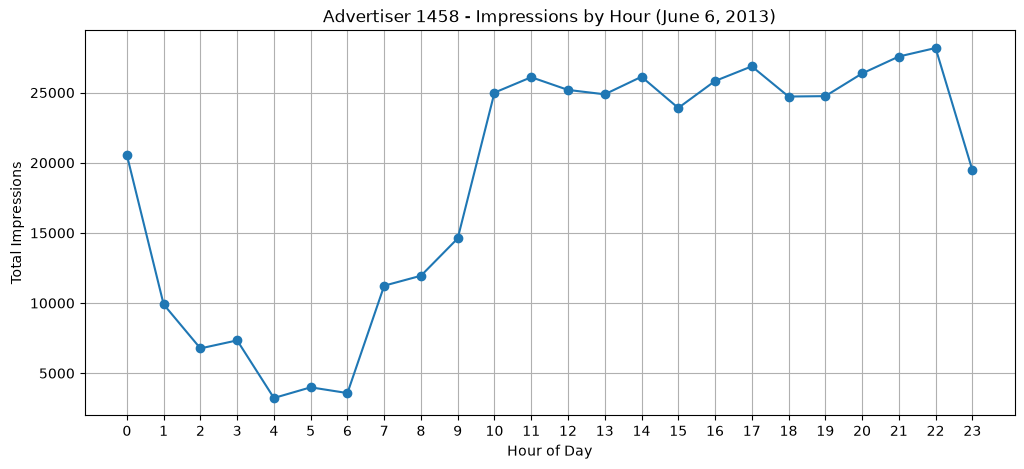

In [215]:
# Import matplotlib for creating charts
import matplotlib.pyplot as plt

# Create a figure with a suitable size
plt.figure(figsize=(12, 5))

# Draw a line chart of impressions by hour
plt.plot(
    hourly_impressions["hour"],
    hourly_impressions["total_impressions"],
    marker="o"
)

# Add a title and axis labels
plt.title("Advertiser 1458 - Impressions by Hour (June 6, 2013)")
plt.xlabel("Hour of Day")
plt.ylabel("Total Impressions")

# Display every hour on the x-axis
plt.xticks(range(24))

# Add a grid to make values easier to read
plt.grid(True)

# Display the chart
plt.show()

In [216]:
# Analyze impressions by advertising slot dimensions

slot_analysis = con.execute("""
    SELECT
        ad_slot_width,
        ad_slot_height,

        COUNT(*) AS total_impressions,

        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS impression_percentage,

        ROUND(
            AVG(TRY_CAST(paying_price AS DOUBLE)),
            2
        ) AS average_paying_price

    FROM impressions_1458_clean

    GROUP BY
        ad_slot_width,
        ad_slot_height

    ORDER BY total_impressions DESC

    LIMIT 15
""").df()

# Display the 15 most common ad-slot sizes
display(slot_analysis)

,ad_slot_width,ad_slot_height,total_impressions,impression_percentage,average_paying_price
0,1000,90,107514,23.99,63.55
1,728,90,98822,22.05,78.14
2,336,280,96492,21.53,68.16
3,160,600,45876,10.24,69.37
4,300,250,42993,9.59,58.99
5,468,60,20986,4.68,64.59
6,250,250,20000,4.46,62.06
7,960,90,15481,3.45,41.95


In [217]:
# Check how many different creatives use each ad-slot size

creative_slot_check = con.execute("""
    SELECT
        ad_slot_width,
        ad_slot_height,

        COUNT(DISTINCT creative_id) AS unique_creatives,

        STRING_AGG(
            DISTINCT creative_id,
            ', '
        ) AS creative_ids

    FROM impressions_1458_clean

    GROUP BY
        ad_slot_width,
        ad_slot_height

    ORDER BY
        COUNT(*) DESC
""").df()

# Display the relationship between ad-slot sizes and creatives
display(creative_slot_check)

,ad_slot_width,ad_slot_height,unique_creatives,creative_ids
0,1000,90,1,832b91d59d0cb5731431653204a76c0e
1,728,90,1,48f2e9ba15708c0146bda5e1dd653caa
2,336,280,1,77819d3e0b3467fe5c7b16d68ad923a1
3,160,600,1,cb7c76e7784031272e37af8e7e9b062c
4,300,250,1,a499988a822facd86dd0e8e4ffef8532
5,468,60,1,612599432d200b093719dd1f372f7a30
6,250,250,1,2abc9eaf57d17a96195af3f63c45dc72
7,960,90,1,fb5afa9dba1274beaf3dad86baf97e89


In [218]:
# Analyze impression distribution across regions

region_analysis = con.execute("""
    SELECT
        region,

        COUNT(*) AS total_impressions,

        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS impression_percentage,

        ROUND(
            AVG(TRY_CAST(paying_price AS DOUBLE)),
            2
        ) AS average_paying_price

    FROM impressions_1458_clean

    GROUP BY region

    ORDER BY total_impressions DESC

    LIMIT 15
""").df()

# Display the 15 regions with the most impressions
display(region_analysis)

,region,total_impressions,impression_percentage,average_paying_price
0,216,53534,11.95,66.30
1,80,35204,7.86,67.39
2,146,29147,6.50,65.06
3,276,25948,5.79,61.52
4,94,22997,5.13,70.81
5,3,21220,4.73,66.79
6,164,20990,4.68,65.86
7,1,20212,4.51,76.96
8,183,17864,3.99,68.12
9,40,16322,3.64,64.62


In [219]:
# Analyze impression distribution across cities

city_analysis = con.execute("""
    SELECT
        region,
        city,

        COUNT(*) AS total_impressions,

        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS impression_percentage,

        ROUND(
            AVG(TRY_CAST(paying_price AS DOUBLE)),
            2
        ) AS average_paying_price

    FROM impressions_1458_clean

    GROUP BY
        region,
        city

    ORDER BY total_impressions DESC

    LIMIT 20
""").df()

# Display the 20 most active region-city combinations
display(city_analysis)

,region,city,total_impressions,impression_percentage,average_paying_price
0,1,1,20212,4.51,76.96
1,216,219,16605,3.71,65.26
2,216,217,14191,3.17,67.49
3,79,79,12148,2.71,86.50
4,275,275,11727,2.62,63.02
5,80,85,9722,2.17,65.97
6,276,277,9542,2.13,63.12
7,333,334,7554,1.69,65.82
8,2,2,7465,1.67,69.55
9,0,0,6897,1.54,58.86


In [220]:
# Analyze clicks by advertising exchange

click_exchange_analysis = con.execute("""
    SELECT
        ad_exchange,

        COUNT(*) AS total_clicks,

        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS click_percentage

    FROM clicks_1458_clean

    GROUP BY ad_exchange

    ORDER BY total_clicks DESC
""").df()

# Display click distribution by exchange
display(click_exchange_analysis)

,ad_exchange,total_clicks,click_percentage
0,2,120,34.58
1,3,117,33.72
2,1,110,31.70


In [221]:
# Compare impression and click counts across advertising exchanges

exchange_comparison = con.execute("""
    SELECT
        i.ad_exchange,

        i.total_impressions,

        c.total_clicks,

        ROUND(
            100.0 * c.total_clicks /
            i.total_impressions,
            4
        ) AS basic_click_to_impression_ratio

    FROM (
        SELECT
            ad_exchange,
            COUNT(*) AS total_impressions
        FROM impressions_1458_clean
        GROUP BY ad_exchange
    ) i

    JOIN (
        SELECT
            ad_exchange,
            COUNT(*) AS total_clicks
        FROM clicks_1458_clean
        GROUP BY ad_exchange
    ) c

    ON i.ad_exchange = c.ad_exchange

    ORDER BY i.ad_exchange
""").df()

# Display the exchange-level comparison
display(exchange_comparison)

,ad_exchange,total_impressions,total_clicks,basic_click_to_impression_ratio
0,1,150777,110,0.0730
1,2,131399,120,0.0913
2,3,165988,117,0.0705


In [222]:
# Create a summary of the main campaign metrics

campaign_summary = pd.DataFrame({
    "metric": [
        "Total bids",
        "Total impressions",
        "Total clicks",
        "Total conversions (June 6-12)",
        "Unique creatives",
        "Advertising exchanges"
    ],

    "value": [
        3250536,
        448164,
        347,
        1,
        8,
        3
    ]
})

# Display the final campaign summary
display(campaign_summary)

,metric,value
0,Total bids,3250536
1,Total impressions,448164
2,Total clicks,347
3,Total conversions (June 6-12),1
4,Unique creatives,8
5,Advertising exchanges,3


# 8. Key Findings and Limitations

## 8.1 Key Findings

The analysis of iPinYou advertiser 1458 produced the following findings:

- The bid dataset contains 3,250,536 records.
- The impression dataset contains 448,164 records.
- The click dataset contains 347 records.
- The conversion dataset contains only 1 conversion across June 6–12, 2013.
- The campaign used 8 different creatives across 3 advertising exchanges.
- The bidding price was consistently 300 in the analyzed bid records.
- Creative `832b91d59d0cb5731431653204a76c0e` generated the highest number of impressions, representing 23.99% of all impressions.
- Exchange 3 accounted for the largest share of impressions (37.04%).
- Impression activity was highest at 22:00.

## 8.2 Data Limitations

Several limitations should be considered when interpreting the results:

1. Only one conversion was recorded during the seven-day conversion period.
2. Bid IDs are not guaranteed to be unique, making exact event matching difficult.
3. Aggregate bid, impression, and click counts do not establish verified auction win rates or attributed click-through rates.
4. Geographic region and city values are numeric codes without confirmed geographic names.
5. Each creative corresponds to only one ad-slot dimension in the analyzed impression data.
6. The bid, impression, and click analysis primarily covers June 6, while conversion analysis covers June 6–12.

## 8.3 Conclusion

This project demonstrates how raw real-time bidding data can be inspected, ingested, cleaned, validated, and analyzed using Python, Pandas, DuckDB, SQL, and Parquet.

The analysis provides an overview of advertiser 1458's bidding activity, impressions, clicks, creatives, and advertising exchanges.

The findings are exploratory and should be interpreted in consideration of the dataset's limitations.